# Servicio de IA de TrazaRed HUV: modelo de urgencia y agrupamiento de pacientes

Este cuaderno hace **dos trabajos distintos que se complementan**:

| Parte | Tipo de aprendizaje | Pregunta que responde | Cómo se compara |
|---|---|---|---|
| Modelo de urgencia | **Supervisado** (hay etiqueta: el KTAS del experto) | ¿Este paciente es urgente? | AUC en validación cruzada |
| Agrupamiento | **No supervisado** (no se usa la etiqueta) | ¿Qué perfiles de paciente existen y dónde se equivoca el modelo? | Silueta, Davies-Bouldin, BIC, ARI y utilidad para el sistema |

No se puede poner a un clasificador y a un algoritmo de agrupamiento en el mismo ranking: responden preguntas distintas y se miden distinto. Por eso cada familia se compara **entre sus pares** y al final se unen en una sola conclusión.

**Orden del cuaderno:** datos y limpieza → separación 80/20 y preprocesamiento → **comparación de modelos supervisados y elección** → modelo final: evaluación en prueba, umbrales y sesgo → guardado → agrupamiento → **comparación de algoritmos de agrupamiento** → pacientes sintéticos → **conclusión final**.

---

## Carga y exploración inicial de los datos (EDA)

Se localiza y carga `ktas.csv` mediante una ruta relativa al proyecto. Se verifican las dimensiones, columnas, tipos de datos y primeras filas del dataset.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, confusion_matrix, precision_score, f1_score
import joblib, sklearn
from datetime import datetime
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt
from sklearn.model_selection import cross_val_predict

In [2]:
actual = Path.cwd()

# Si estamos dentro de notebooks, subir un nivel
if actual.name == "notebooks":
    actual = actual.parent

ruta_csv = None

for carpeta in [actual, *actual.parents]:
    candidato = carpeta / "ml" / "data" / "ktas.csv"

    if candidato.is_file():
        ruta_csv = candidato
        break
    
# Comprobar que existe
if ruta_csv is None:
    raise FileNotFoundError(
        f"No se encontró ktas.csv desde la carpeta: {Path.cwd()}\n"
        "Verifica que el archivo esté en ml/data/ktas.csv."
    )
df = pd.read_csv(ruta_csv, sep=";", encoding="latin-1")

print("Archivo encontrado:", ruta_csv.resolve())


Archivo encontrado: C:\Users\Admin\Downloads\ET-Project\TrazaRedHUV\ml\data\ktas.csv


In [3]:
# Revisamos el dataset

print(df.shape)
print(df.columns.tolist())
print(df.dtypes)
df.head(3)

(1267, 24)
['Group', 'Sex', 'Age', 'Patients number per hour', 'Arrival mode', 'Injury', 'Chief_complain', 'Mental', 'Pain', 'NRS_pain', 'SBP', 'DBP', 'HR', 'RR', 'BT', 'Saturation', 'KTAS_RN', 'Diagnosis in ED', 'Disposition', 'KTAS_expert', 'Error_group', 'Length of stay_min', 'KTAS duration_min', 'mistriage']
Group                        int64
Sex                          int64
Age                          int64
Patients number per hour     int64
Arrival mode                 int64
Injury                       int64
Chief_complain              object
Mental                       int64
Pain                         int64
NRS_pain                    object
SBP                         object
DBP                         object
HR                          object
RR                          object
BT                          object
Saturation                  object
KTAS_RN                      int64
Diagnosis in ED             object
Disposition                  int64
KTAS_expert          

,Group,Sex,Age,Patients number per hour,Arrival mode,Injury,Chief_complain,Mental,Pain,NRS_pain,...,BT,Saturation,KTAS_RN,Diagnosis in ED,Disposition,KTAS_expert,Error_group,Length of stay_min,KTAS duration_min,mistriage
0,2,2,71,3,3,2,right ocular pain,1,1,2,...,36.6,100,2,Corneal abrasion,1,4,2,86,"5,00",1
1,1,1,56,12,3,2,right forearm burn,1,1,2,...,36.5,NaN,4,"Burn of hand, firts degree dorsum",1,5,4,64,"3,95",1
2,2,1,68,8,2,2,"arm pain, Lt",1,1,2,...,36.6,98,4,"Fracture of surgical neck of humerus, closed",2,5,4,862,"1,00",1


### Revisión de valores atípicos y distribución de la etiqueta

Se identifican valores inválidos (`??`, `#BOÞ!`) y se examina la distribución de las categorías `KTAS_expert`.

In [4]:

raros = ["??", "#BOÞ!"]
print("Celdas raras por columna:")
print((df.isin(raros)).sum()[lambda s: s > 0])

# Cómo se reparte la etiqueta KTAS 
print(df["KTAS_expert"].value_counts().sort_index())

Celdas raras por columna:
Chief_complain      5
NRS_pain          556
SBP                25
DBP                29
HR                 20
RR                 22
BT                 18
Saturation          9
dtype: int64
KTAS_expert
1     26
2    220
3    487
4    459
5     75
Name: count, dtype: int64



### Definición de la etiqueta y selección de variables


**Etiqueta objetivo.** Se define como *urgente* a un paciente con clasificación KTAS 1, 2 o 3, y como *no urgente* a uno con KTAS 4 o 5. Según el conteo realizado, hay 733 pacientes urgentes y 534 no urgentes, por lo que las clases están relativamente equilibradas.

**Variables de entrada.** Se utilizan únicamente variables disponibles al momento de la llegada del paciente:

- **Demográficas:** `Sex`, `Age`.
- **Operativas y de llegada:** `Patients number per hour`, `Arrival mode`, `Injury`.
- **Evaluación inicial:** `Mental`, `Pain`, `NRS_pain`, `SBP`, `DBP`, `HR`, `RR`, `BT`, `Saturation`.

La variable `Group`, correspondiente al hospital, se reserva para el análisis de sesgo y no se utiliza como variable de entrada del modelo.

**Variables excluidas.** Se excluyen `KTAS_RN`, `Diagnosis in ED`, `Disposition`, `Error_group`, `Length of stay_min`, `KTAS duration_min` y `mistriage`, porque corresponden a información posterior o relacionada con el proceso de atención. También se excluye `Chief_complain`, por decisión metodológica, ya que el modelo no utilizará el motivo de consulta. Finalmente, `KTAS_expert` se utiliza exclusivamente como etiqueta objetivo para el entrenamiento y la evaluación, nunca como variable de entrada.

----

### Limpieza de los datos 

In [5]:
raros = ["??", "#BOÞ!"]
df = df.replace(raros, np.nan)

num = ["NRS_pain", "SBP", "DBP", "HR", "RR", "BT", "Saturation"]
for c in num:
    df[c] = pd.to_numeric(df[c], errors="coerce")

df["urgente"] = (df["KTAS_expert"] <= 3).astype(int)
print(df["urgente"].value_counts())
print(df[num].isna().sum())

urgente
1    733
0    534
Name: count, dtype: int64
NRS_pain      556
SBP            25
DBP            29
HR             20
RR             22
BT             18
Saturation    697
dtype: int64


In [6]:
print(pd.crosstab(df["Pain"], df["NRS_pain"].isna()))
print(df["Arrival mode"].value_counts().sort_index())

NRS_pain  False  True 
Pain                  
0             0    553
1           711      3
Arrival mode
1     79
2    266
3    753
4    155
5      2
6     10
7      2
Name: count, dtype: int64


In [7]:
df.loc[df["Pain"] == 0, "NRS_pain"] = 0
df["Arrival mode"] = df["Arrival mode"].replace({6: 5, 7: 5})

print(df["NRS_pain"].isna().sum())          # deberían ser 3
print(df["Arrival mode"].value_counts().sort_index())

3
Arrival mode
1     79
2    266
3    753
4    155
5     14
Name: count, dtype: int64


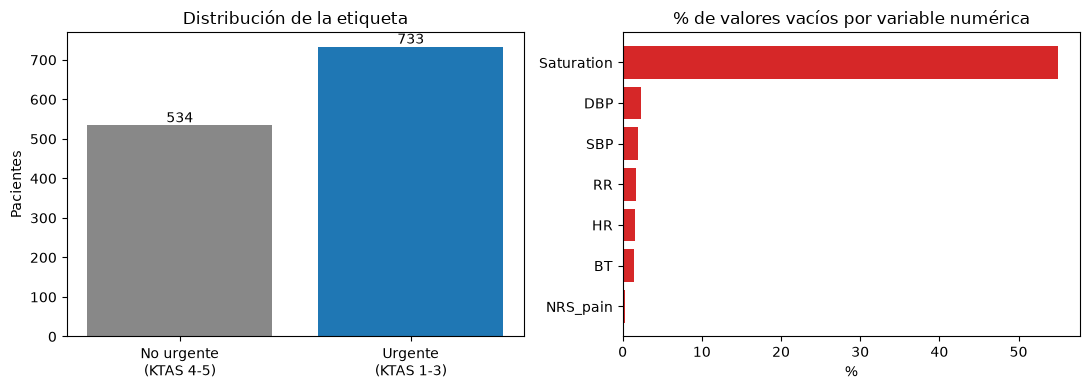

In [8]:
# Etiqueta y datos faltantes, de un vistazo
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

n_ur = int(df["urgente"].sum())
n_no = int((df["urgente"] == 0).sum())
ax[0].bar(["No urgente\n(KTAS 4-5)", "Urgente\n(KTAS 1-3)"], [n_no, n_ur], color=["#888888", "#1f77b4"])
for i_, v_ in enumerate([n_no, n_ur]):
    ax[0].text(i_, v_ + 8, str(v_), ha="center")
ax[0].set_title("Distribución de la etiqueta")
ax[0].set_ylabel("Pacientes")

faltantes = (df[num].isna().mean() * 100).sort_values()
ax[1].barh(faltantes.index, faltantes.values, color="#d62728")
ax[1].set_title("% de valores vacíos por variable numérica")
ax[1].set_xlabel("%")

plt.tight_layout()
plt.show()

- Las clases están razonablemente equilibradas (733 urgentes y 534 no urgentes)
- saturation es la única variable con muchos valores vacíos (55%)
- Las demás variables tienen menos del 3% de valores faltantes
- La imputación con la mediana afecta principalmente a saturation

### Limpieza de KTAS (1267 filas, 24 columnas)
- Los valores `??` y `#BOÞ!` pasaron a vacío y las columnas numéricas se convirtieron a número.
- Etiqueta: `urgente` = KTAS del experto 1, 2 o 3 (733 urgentes, 534 no urgentes).
- `NRS_pain`: los 553 vacíos de pacientes sin dolor (`Pain = 0`) se rellenaron con 0; quedan 3 vacíos (dolor sí, pero sin escala registrada).
- `Arrival mode`: los códigos 5, 6 y 7 (2, 10 y 2 pacientes) se juntaron en uno (14 pacientes).
- `Saturation` tiene 697 vacíos (55 %): la mediana imputa más de la mitad de los casos. Se declara como limitación.
- Los demás vacíos son pocos (18 a 29 por variable) y se imputan con la mediana dentro del pipeline.
- No entran al modelo: las variables posteriores a la llegada (`KTAS_RN`, `Diagnosis in ED`, `Disposition`, `Error_group`, `Length of stay_min`, `KTAS duration_min`, `mistriage`) ni `Chief_complain`. `Group` (hospital) se guarda aparte solo para el análisis de sesgo.

---
## Preparación de los datos

**Separación 80/20.**

El 80 % se utiliza para entrenar y el 20 % se reserva para la evaluación final. `stratify=y` conserva la proporción de clases y `random_state=42` permite reproducir la separación


In [9]:
#Definimos las columnas

cols_num = ["Age", "Patients number per hour", "NRS_pain", "SBP", "DBP", "HR", "RR", "BT", "Saturation"]
cols_cat = ["Sex", "Arrival mode", "Injury", "Mental", "Pain"]

X = df[cols_num + cols_cat]
y = df["urgente"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
print(X_train.shape, X_test.shape)
print(y_train.mean().round(3), y_test.mean().round(3))

(1013, 14) (254, 14)
0.578 0.579


- Se seleccionaron 14 variables predictoras: 9 numéricas y 5 categóricas.
- Los datos se dividieron en un 80% para entrenamiento (1.013 pacientes) y un 20% para prueba (254 pacientes)
- Se utilizó `stratify=y` para conservar una proporción similar de pacientes urgentes y no urgentes en ambos grupos
- La proporcion de pacientes urgentes fue del 57,8% en entrenamiento y del 57,9% en prueba lo que indica que la distribución de la variable objetivo se mantuvo equilibrada entre las particiones

---

### **Pipeline de preprocesamiento.**

Agrupa las transformaciones para evitar la fuga de información (data leakage)

- **Numéricas:** imputación con la mediana y escalado con `StandardScaler`.
- **Categóricas:** codificación *One-Hot*.

In [10]:
pre = ColumnTransformer([
    ("num", Pipeline([("mediana", SimpleImputer(strategy="median")),
                      ("escala", StandardScaler())]), cols_num),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cols_cat),
])

# Las mismas 5 particiones se usarán para comparar TODOS los modelos
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

---
# Elección del modelo supervisado

**Todavía no hay modelo elegido.** Aquí se comparan, en igualdad de condiciones, todos los candidatos: regresión logística, árbol de decisión, KNN, SVM (lineal y rbf), Gradient Boosting, XGBoost, LightGBM, CatBoost y dos redes MLP. La regresión lineal entra solo como referencia. **El que gane se usa para todo lo que sigue** (evaluación en prueba, umbrales, sesgo y guardado).

**Reglas del experimento, fijadas antes de ver resultados:**

1. Todos los modelos reciben **el mismo preprocesamiento** (mediana → estandarización → one-hot) dentro de un `Pipeline`, así que ninguno ve información de validación al calcular medianas o escalas.
2. Todos usan **las mismas 5 particiones** de validación cruzada, calculadas sobre el entrenamiento.
3. **Se elige por AUC en validación cruzada**, no por el rendimiento en entrenamiento (premia memorizar). **La prueba no se toca en esta sección:** se usa una sola vez, después, con el modelo elegido. Así sigue siendo una medida independiente.
4. Si varios modelos quedan **dentro de una desviación estándar** del mejor, se consideran empatados y gana el más explicable, siguiendo este orden: regresión logística, árbol, SVM lineal, KNN, boosting, SVM rbf, redes.
5. Los umbrales y el sesgo de las secciones siguientes se recalculan solos con el modelo elegido. Los textos escritos a mano y `entrenar.py` están redactados para la regresión logística: si gana otro modelo, hay que revisarlos.

In [11]:
# Solo la primera vez. Si instala algo nuevo, reinicie el kernel y ejecute el cuaderno desde el principio.
# %pip install -q xgboost lightgbm catboost

In [12]:
import time, warnings
from sklearn.base import clone
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_validate


# (KNN, boosting y redes trabajan más cómodos así). clone() crea una copia SIN entrenar

try:
    pre_d = clone(pre).set_params(cat__sparse_output=False)
except ValueError:                      # versiones antiguas de scikit-learn
    pre_d = clone(pre).set_params(cat__sparse=False)

candidatos = {
    "Regresión logística": LogisticRegression(max_iter=1000),
    "Árbol de decisión":   DecisionTreeClassifier(max_depth=3, random_state=42),
    "KNN":                 KNeighborsClassifier(n_neighbors=15),
    "SVM lineal":          SVC(kernel="linear", probability=True, random_state=42),
    "SVM rbf":             SVC(kernel="rbf", C=1.0, probability=True, random_state=42),
    "Gradient Boosting":   GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, max_depth=3, random_state=42),
    "MLP sin regularizar": MLPClassifier(hidden_layer_sizes=(16, 8), alpha=1e-4, max_iter=3000, random_state=42),
    "MLP regularizado":    MLPClassifier(hidden_layer_sizes=(16,), alpha=1.0, max_iter=3000, random_state=42),
}

# Las tres librerías de boosting modernas son opcionales: si no están, se omiten.
try:
    from xgboost import XGBClassifier
    candidatos["XGBoost"] = XGBClassifier(n_estimators=200, max_depth=3, learning_rate=0.05, random_state=42)
except Exception as e_:
    print("XGBoost no disponible, se omite:", type(e_).__name__)
try:
    from lightgbm import LGBMClassifier
    candidatos["LightGBM"] = LGBMClassifier(n_estimators=200, learning_rate=0.05, num_leaves=15, random_state=42, verbose=-1)
except Exception as e_:
    print("LightGBM no disponible, se omite:", type(e_).__name__)
try:
    from catboost import CatBoostClassifier
    candidatos["CatBoost"] = CatBoostClassifier(iterations=300, depth=4, learning_rate=0.05, verbose=0, random_seed=42)
except Exception as e_:
    print("CatBoost no disponible, se omite:", type(e_).__name__)

# Orden de preferencia por explicabilidad, usado SOLO para desempatar (regla 4)
ORDEN_EXPLICABILIDAD = ["Regresión logística", "Árbol de decisión", "SVM lineal", "KNN",
                        "Gradient Boosting", "XGBoost", "LightGBM", "CatBoost",
                        "SVM rbf", "MLP regularizado", "MLP sin regularizar"]

print(len(candidatos), "modelos a comparar:", list(candidatos))

11 modelos a comparar: ['Regresión logística', 'Árbol de decisión', 'KNN', 'SVM lineal', 'SVM rbf', 'Gradient Boosting', 'MLP sin regularizar', 'MLP regularizado', 'XGBoost', 'LightGBM', 'CatBoost']


In [13]:
def evaluar_candidato(nombre, clf):
    pipe = Pipeline([("pre", clone(pre_d)), ("clf", clone(clf))])
    t0 = time.time()
    r = cross_validate(pipe, X_train, y_train, cv=cv, return_train_score=True,
                       scoring={"auc": "roc_auc", "brier": "neg_brier_score"})
    return {"modelo": nombre,
            "AUC_cv": r["test_auc"].mean(),
            "desviacion": r["test_auc"].std(),
            "AUC_entrenamiento": r["train_auc"].mean(),
            "brecha": r["train_auc"].mean() - r["test_auc"].mean(),
            "Brier_cv": -r["test_brier"].mean(),
            "segundos": round(time.time() - t0, 1)}

filas = []
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    for nombre, clf in candidatos.items():
        filas.append(evaluar_candidato(nombre, clf))
        print(f"{nombre:22s} AUC_cv {filas[-1]['AUC_cv']:.3f} ± {filas[-1]['desviacion']:.3f}")

tabla_sup = pd.DataFrame(filas).set_index("modelo").sort_values("AUC_cv", ascending=False)
tabla_sup.round(3)

Regresión logística    AUC_cv 0.809 ± 0.011
Árbol de decisión      AUC_cv 0.729 ± 0.025


  File "c:\Users\Admin\Downloads\ET-Project\TrazaRedHUV\.venv\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "C:\Users\Admin\AppData\Local\Programs\Python\Python313\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\Admin\AppData\Local\Programs\Python\Python313\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
                        pass_fds, cwd, env,
                        ^^^^^^^^^^^^^^^^^^^
    ...<5 lines>...
                        gid, gids, uid, umask,
                        ^^^^^^^^^^^^^^^^^^^^^^
                        start_new_session, process_group)
                 

KNN                    AUC_cv 0.753 ± 0.012
SVM lineal             AUC_cv 0.809 ± 0.015
SVM rbf                AUC_cv 0.798 ± 0.010
Gradient Boosting      AUC_cv 0.824 ± 0.012
MLP sin regularizar    AUC_cv 0.806 ± 0.014
MLP regularizado       AUC_cv 0.802 ± 0.014
XGBoost                AUC_cv 0.833 ± 0.005
LightGBM               AUC_cv 0.811 ± 0.017
CatBoost               AUC_cv 0.829 ± 0.008


,AUC_cv,desviacion,AUC_entrenamiento,brecha,Brier_cv,segundos
modelo,,,,,,
XGBoost,0.833,0.005,0.928,0.094,0.165,3.5
CatBoost,0.829,0.008,0.972,0.143,0.167,4.1
Gradient Boosting,0.824,0.012,0.949,0.125,0.169,1.9
LightGBM,0.811,0.017,0.995,0.184,0.178,1.8
Regresión logística,0.809,0.011,0.827,0.018,0.175,0.6
SVM lineal,0.809,0.015,0.820,0.012,0.177,2.2
MLP sin regularizar,0.806,0.014,0.934,0.128,0.184,9.5
MLP regularizado,0.802,0.014,0.835,0.033,0.180,3.1
SVM rbf,0.798,0.010,0.884,0.085,0.180,3.0


----

### Regresión lineal: ¿por qué no entra al ranking?

La regresión lineal predice un número, no una clase. Se puede forzar: entrenarla sobre la etiqueta 0/1 (un «modelo de probabilidad lineal»). Pero entonces sus salidas no son probabilidades: pueden dar valores negativos o mayores que 1, y los umbrales (0.4 y 0.9) pierden su significado. Se incluye como **referencia**: el AUC solo necesita ordenar pacientes, así que sí se puede calcular, pero el modelo no es apto para umbrales.

In [14]:
aucs_lin, fuera_lin, mins_lin, maxs_lin = [], [], [], []
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    for tr_, va_ in cv.split(X_train, y_train):
        reg_ = Pipeline([("pre", clone(pre_d)), ("clf", LinearRegression())])
        reg_.fit(X_train.iloc[tr_], y_train.iloc[tr_])
        p_ = reg_.predict(X_train.iloc[va_])
        aucs_lin.append(roc_auc_score(y_train.iloc[va_], p_))
        fuera_lin.append(((p_ < 0) | (p_ > 1)).mean() * 100)
        mins_lin.append(p_.min()); maxs_lin.append(p_.max())

ref_lineal = pd.Series({"AUC_cv": np.mean(aucs_lin), "desviacion": np.std(aucs_lin),
                        "salidas_fuera_de_0_1_%": np.mean(fuera_lin),
                        "minimo": min(mins_lin), "maximo": max(maxs_lin)},
                       name="Regresión lineal (referencia)")
print(ref_lineal.round(3).to_string())

AUC_cv                    0.808
desviacion                0.013
salidas_fuera_de_0_1_%    6.606
minimo                   -0.267
maximo                    1.767


 - Ordena a los pacientes igual de bien que la logística (AUC_cv 0,808)
 - pero el 6,6 % de sus salidas cae fuera de [0, 1] (de −0,27 a 1,77)
 - No son probabilidades, así que los umbrales perderían sentido y **no entra al ranking**

### Comparacion final - Graficas

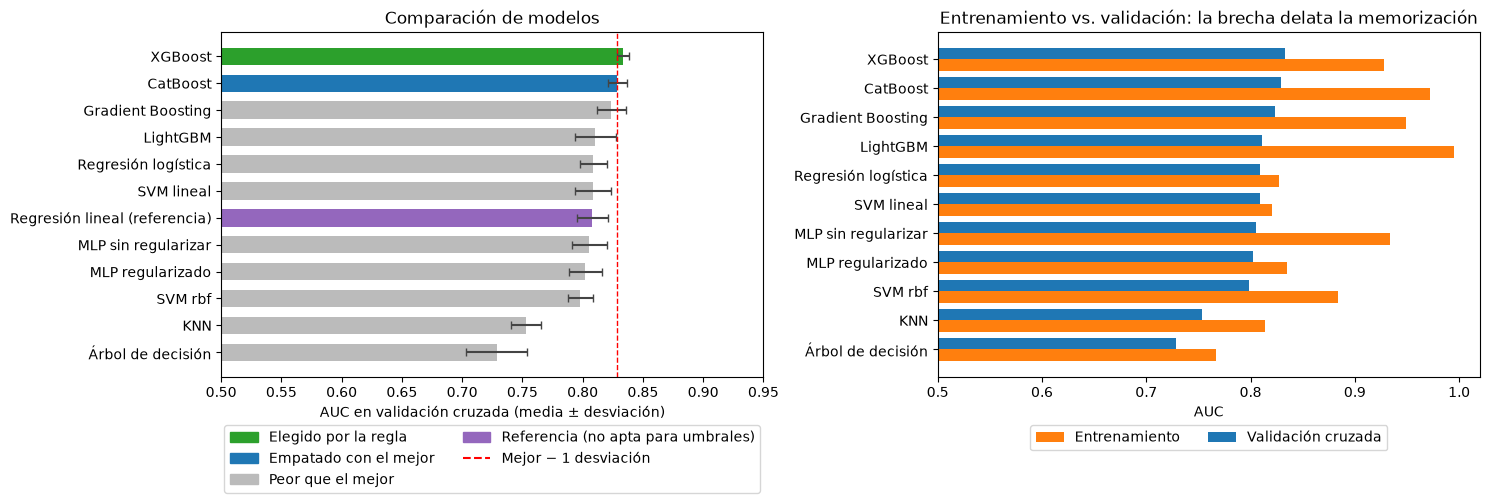

Mejor AUC en validación cruzada: XGBoost (0.833 ± 0.005)
Empatados (AUC_cv >= 0.828): XGBoost, CatBoost
Elegido según la regla de explicabilidad: XGBoost


In [15]:
from matplotlib.patches import Patch

# Regla de decisión (definida arriba): empate = dentro de una desviación del mejor
mejor_sup = tabla_sup["AUC_cv"].idxmax()
corte = tabla_sup.loc[mejor_sup, "AUC_cv"] - tabla_sup.loc[mejor_sup, "desviacion"]
empatados = tabla_sup.index[tabla_sup["AUC_cv"] >= corte].tolist()
elegido_sup = next(m for m in ORDEN_EXPLICABILIDAD if m in empatados)

fig, ax = plt.subplots(1, 2, figsize=(15, 5.2))

# 1) Comparación por validación cruzada (lo que decide)
g = pd.concat([tabla_sup[["AUC_cv", "desviacion"]],
               ref_lineal[["AUC_cv", "desviacion"]].to_frame().T]).sort_values("AUC_cv")
def _color(m_):
    if m_.startswith("Regresión lineal"):
        return "#9467bd"                      # referencia: no apta para umbrales
    return "#2ca02c" if m_ == elegido_sup else "#1f77b4" if m_ in empatados else "#bbbbbb"
colores = [_color(m_) for m_ in g.index]
ax[0].barh(g.index, g["AUC_cv"], xerr=g["desviacion"], color=colores, height=0.65,
           error_kw={"ecolor": "#444444", "capsize": 3})
ax[0].axvline(corte, color="red", ls="--", lw=1)
ax[0].set_xlim(0.5, 0.95)
ax[0].set_xlabel("AUC en validación cruzada (media ± desviación)")
ax[0].set_title("Comparación de modelos")
ax[0].legend(handles=[Patch(color="#2ca02c", label="Elegido por la regla"),
                      Patch(color="#1f77b4", label="Empatado con el mejor"),
                      Patch(color="#bbbbbb", label="Peor que el mejor"),
                      Patch(color="#9467bd", label="Referencia (no apta para umbrales)"),
                      plt.Line2D([0], [0], color="red", ls="--", label="Mejor − 1 desviación")],
             loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2)

# 2) Entrenamiento vs validación: quien memoriza, rinde mucho mejor en entrenamiento que fuera de él
t_ = tabla_sup.sort_values("AUC_cv")
pos = np.arange(len(t_))
ax[1].barh(pos - 0.2, t_["AUC_entrenamiento"], height=0.4, color="#ff7f0e", label="Entrenamiento")
ax[1].barh(pos + 0.2, t_["AUC_cv"], height=0.4, color="#1f77b4", label="Validación cruzada")
ax[1].set_yticks(pos)
ax[1].set_yticklabels(t_.index)
ax[1].set_xlim(0.5, 1.02)
ax[1].set_xlabel("AUC")
ax[1].set_title("Entrenamiento vs. validación: la brecha delata la memorización")
ax[1].legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2)

plt.tight_layout()
plt.show()

print(f"Mejor AUC en validación cruzada: {mejor_sup} ({tabla_sup.loc[mejor_sup, 'AUC_cv']:.3f} ± {tabla_sup.loc[mejor_sup, 'desviacion']:.3f})")
print(f"Empatados (AUC_cv >= {corte:.3f}): {', '.join(empatados)}")
print(f"Elegido según la regla de explicabilidad: {elegido_sup}")

### Comparación de modelos

- **XGBoost** obtuvo el mejor AUC promedio en validación cruzada (0,833 ± 0,005), seguido de **CatBoost** (0,829 ± 0,008).
- Ambos modelos tienen resultados similares, pues la diferencia está dentro de una desviación estándar del mejor resultado. Se eligió XGBoost según el criterio de explicabilidad definido previamente.
- **Regresión logística** obtuvo un AUC de 0,809, 0,024 por debajo del de XGBoost (más explicable, pero con menor poder de ordenar pacientes).
- **Árbol de decisión** (0,729) y **KNN** (0,753) presentaron los AUC más bajos.

### Calidad de las probabilidades

- XGBoost obtuvo el mejor Brier Score (0,165), inferior al valor de referencia de aproximadamente 0,244.
- Esto indica que sus probabilidades tuvieron menor error que las de una predicción constante basada en la proporción de pacientes urgentes.

### Brecha entre entrenamiento y validación

- XGBoost presentó una brecha de 0,094 entre entrenamiento y validación, mientras que LightGBM alcanzó 0,184.
- La regresión logística tuvo una brecha menor (0,018), lo que sugiere una diferencia más pequeña entre ambos conjuntos.
- Las brechas mayores en los modelos de boosting pueden indicar sobreajuste, aunque esto no implica necesariamente un peor rendimiento en datos nuevos.
- XGBoost mantuvo el mejor AUC promedio en validación cruzada, por lo que se seleccionó como el mejor candidato entre los modelos evaluados.

---

### Decisión

Con la comparación hecha, queda escrito qué modelo se usa de aquí en adelante.

In [16]:
print(f"Modelo elegido: {elegido_sup}")
if elegido_sup == "Regresión logística":
    print("Se usa para la evaluación en prueba, los umbrales (0.4 y 0.9), el sesgo y el guardado.")
else:
    print(f"El resto del cuaderno se calculará con {elegido_sup}.")
    print("Recordatorio: confirmar que los textos, los umbrales 0.4 y 0.9 y entrenar.py correspondan a este modelo.")

Modelo elegido: XGBoost
El resto del cuaderno se calculará con XGBoost.
Recordatorio: confirmar que los textos, los umbrales 0.4 y 0.9 y entrenar.py correspondan a este modelo.


### Modelo final

Se construye con el algoritmo elegido arriba, con el mismo preprocesamiento y las mismas particiones, y se entrena con el 80 %. **A partir de aquí todo (prueba, umbrales, sesgo y guardado) usa este modelo.**

In [17]:
modelo = Pipeline([("pre", pre), ("clf", clone(candidatos[elegido_sup]))])

auc_cv = cross_val_score(modelo, X_train, y_train, cv=cv, scoring="roc_auc")
print(auc_cv.round(3), auc_cv.mean().round(3))

modelo.fit(X_train, y_train)

[0.825 0.84  0.836 0.83  0.835] 0.833


Pipeline(steps=[('pre',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('mediana',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('escala',
                                                                   StandardScaler())]),
                                                  ['Age',
                                                   'Patients number per hour',
                                                   'NRS_pain', 'SBP', 'DBP',
                                                   'HR', 'RR', 'BT',
                                                   'Saturation']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Sex', 'Arrival mode',
                                                   'Injury', 'Mental',
                                                   'Pain'])])),
                ('clf',
                 XGBClassi...
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.05,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=3, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=200, n_jobs=None,
                               num_parallel_tree=None, ...))])

---

## Evaluación en el conjunto de prueba

Se evalúa el modelo con el 20 % de los datos reservados, sin utilizarlos durante el entrenamiento.

- **AUC:** mide la capacidad para distinguir entre pacientes urgentes y no urgentes.
- **Umbral:** probabilidad a partir de la cual se clasifica un paciente como urgente.
- **Sensibilidad:** proporción de pacientes urgentes detectados.
- **Especificidad:** proporción de pacientes no urgentes identificados correctamente.
- **Precisión:** proporción de predicciones urgentes que son correctas.
- **F1:** equilibra precisión y sensibilidad.
- **Matriz de confusión:** resume las predicciones correctas e incorrectas, destacando los falsos negativos.

En triage, bajar el umbral a **0.4** puede aumentar la detección de pacientes urgentes, aunque también genere más falsas alarmas.

In [18]:
proba = modelo.predict_proba(X_test)[:, 1]
print("AUC prueba:", round(roc_auc_score(y_test, proba), 3))

def metricas(umbral):
    pred = (proba >= umbral).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    return {"umbral": umbral,
            "sens": round(tp / (tp + fn), 3), "espec": round(tn / (tn + fp), 3),
            "prec": round(precision_score(y_test, pred), 3), "f1": round(f1_score(y_test, pred), 3),
            "TN": tn, "FP": fp, "FN": fn, "TP": tp}

pd.DataFrame([metricas(u) for u in [0.5, 0.4, 0.3]])

AUC prueba: 0.762


,umbral,sens,espec,prec,f1,TN,FP,FN,TP
0,0.5,0.803,0.570,0.720,0.759,61,46,29,118
1,0.4,0.884,0.523,0.718,0.793,56,51,17,130
2,0.3,0.918,0.393,0.675,0.778,42,65,12,135


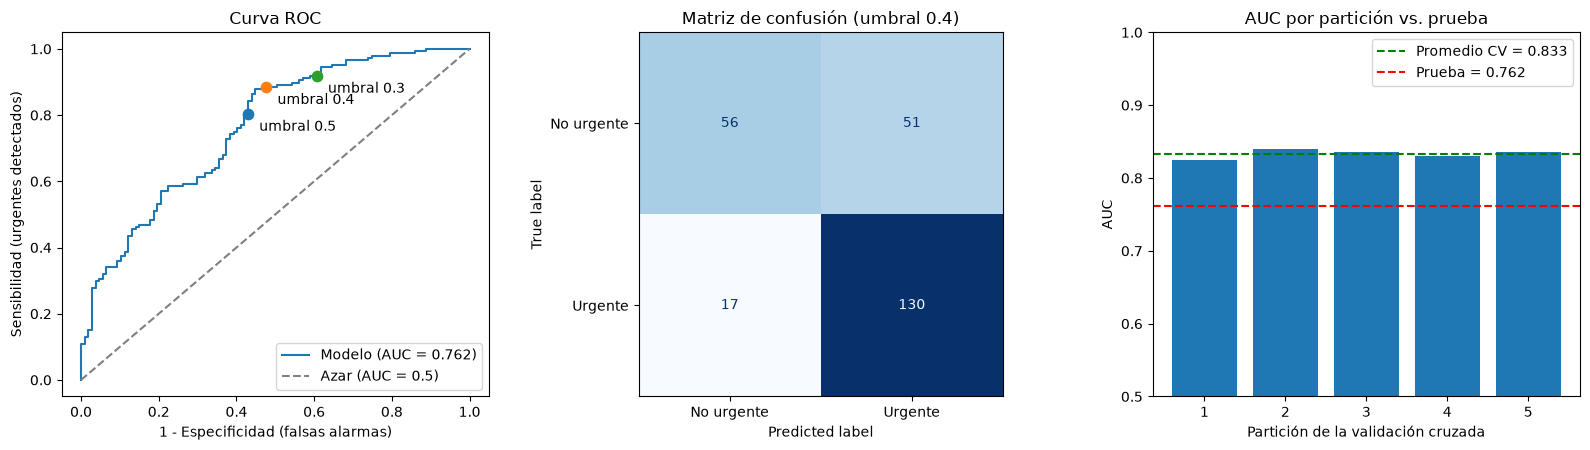

In [19]:
from sklearn.metrics import roc_curve, ConfusionMatrixDisplay

fig, ax = plt.subplots(1, 3, figsize=(16, 4.6))

# 1) Curva ROC con los umbrales marcados
fpr, tpr, _ = roc_curve(y_test, proba)
ax[0].plot(fpr, tpr, label=f"Modelo (AUC = {roc_auc_score(y_test, proba):.3f})")
ax[0].plot([0, 1], [0, 1], "--", color="gray", label="Azar (AUC = 0.5)")
for u in [0.5, 0.4, 0.3]:
    mu = metricas(u)
    ax[0].scatter(1 - mu["espec"], mu["sens"], s=55, zorder=3)
    ax[0].annotate(f"umbral {u}", (1 - mu["espec"], mu["sens"]), textcoords="offset points", xytext=(8, -12))
ax[0].set_xlabel("1 - Especificidad (falsas alarmas)")
ax[0].set_ylabel("Sensibilidad (urgentes detectados)")
ax[0].set_title("Curva ROC")
ax[0].legend(loc="lower right")

# 2) Matriz de confusión con el umbral elegido
ConfusionMatrixDisplay.from_predictions(
    y_test, (proba >= 0.4).astype(int),
    display_labels=["No urgente", "Urgente"], cmap="Blues", ax=ax[1], colorbar=False)
ax[1].set_title("Matriz de confusión (umbral 0.4)")

# 3) Estabilidad: AUC de cada partición de la validación cruzada frente al AUC de prueba
ax[2].bar(range(1, 6), auc_cv, color="#1f77b4")
ax[2].axhline(auc_cv.mean(), color="green", ls="--", label=f"Promedio CV = {auc_cv.mean():.3f}")
ax[2].axhline(roc_auc_score(y_test, proba), color="red", ls="--", label=f"Prueba = {roc_auc_score(y_test, proba):.3f}")
ax[2].set_ylim(0.5, 1)
ax[2].set_xlabel("Partición de la validación cruzada")
ax[2].set_ylabel("AUC")
ax[2].set_title("AUC por partición vs. prueba")
ax[2].legend()

plt.tight_layout()
plt.show()

### Evaluación del modelo en prueba

- Las cinco particiones de validación cruzada obtuvieron AUC entre 0,825 y 0,840, lo que indica resultados bastante estables.
- En el conjunto de prueba, XGBoost obtuvo un AUC de 0,762, inferior al promedio de validación cruzada (0,833).
- Esto podría indicar que los 254 pacientes del conjunto de prueba son más difíciles de clasificar. Sin embargo, no se puede confirmar únicamente con estos resultados.
- Con 254 pacientes, el error de estimación del AUC puede ser considerable (aproximadamente 0,03, según la distribución de los datos). La diferencia de 0,071 entre validación y prueba no debe atribuirse completamente al azar.
- Por tanto, el AUC de prueba (0,762) es la estimación más directa del rendimiento en datos no utilizados durante el entrenamiento y conviene reportarlo como resultado principal de la evaluación final.

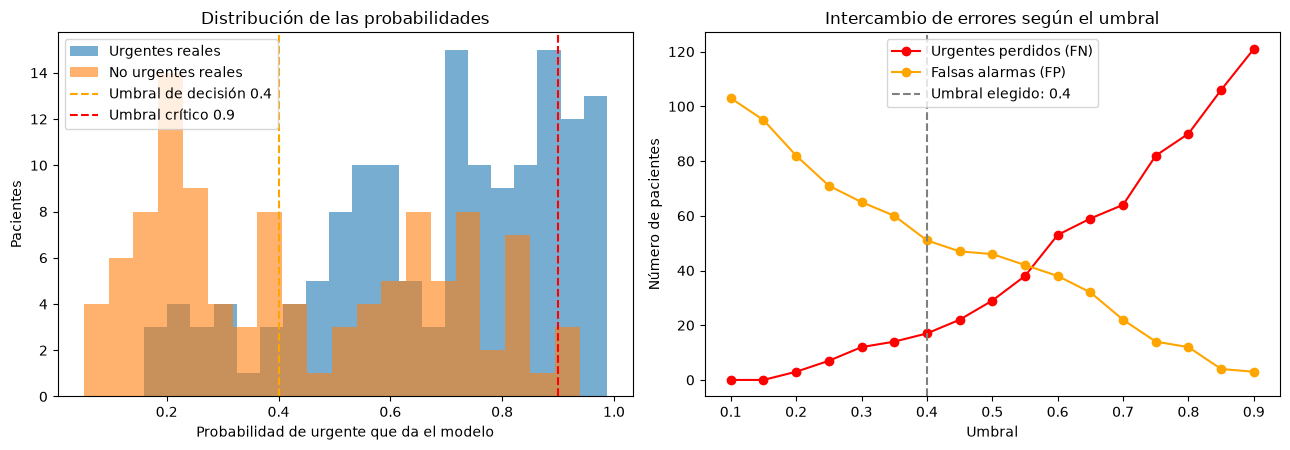

In [20]:
yt = y_test.values
fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))

# 1) Cómo reparte el modelo sus probabilidades
ax[0].hist(proba[yt == 1], bins=20, alpha=0.6, label="Urgentes reales")
ax[0].hist(proba[yt == 0], bins=20, alpha=0.6, label="No urgentes reales")
ax[0].axvline(0.4, color="orange", ls="--", label="Umbral de decisión 0.4")
ax[0].axvline(0.9, color="red", ls="--", label="Umbral crítico 0.9")
ax[0].set_xlabel("Probabilidad de urgente que da el modelo")
ax[0].set_ylabel("Pacientes")
ax[0].set_title("Distribución de las probabilidades")
ax[0].legend()

# 2) Intercambio entre urgentes perdidos y falsas alarmas según el umbral
us = np.arange(0.1, 0.91, 0.05)
fn_ = [int(((proba < u) & (yt == 1)).sum()) for u in us]
fp_ = [int(((proba >= u) & (yt == 0)).sum()) for u in us]
ax[1].plot(us, fn_, "o-", color="red", label="Urgentes perdidos (FN)")
ax[1].plot(us, fp_, "o-", color="orange", label="Falsas alarmas (FP)")
ax[1].axvline(0.4, color="gray", ls="--", label="Umbral elegido: 0.4")
ax[1].set_xlabel("Umbral")
ax[1].set_ylabel("Número de pacientes")
ax[1].set_title("Intercambio de errores según el umbral")
ax[1].legend()

plt.tight_layout()
plt.show()

### Selección del umbral de clasificación

- Con un umbral de **0,4**, el modelo obtuvo una sensibilidad de 0,884, especificidad de 0,523, precisión de 0,718 y F1 de 0,793.
- Con este umbral se pierden 17 pacientes urgentes y se generan 51 falsas alarmas.
- Al bajar el umbral de 0,5 a 0,4, se reducen los pacientes urgentes no detectados de 29 a 17, a cambio de 5 falsas alarmas adicionales.
- Al bajar el umbral de 0,4 a 0,3, solo se detectan 5 pacientes urgentes adicionales, pero las falsas alarmas aumentan de 51 a 65.
- El umbral de 0,4 obtiene el mayor F1 (0,793), frente a 0,759 con 0,5 y 0,778 con 0,3.

**Conclusión:** se mantiene el umbral de 0,4 porque ofrece el mejor F1 de los tres umbrales evaluados y permite reducir los casos urgentes no detectados sin aumentar excesivamente las falsas alarmas, pero principalmente porque en triage perder un urgente es peor que una falsa alarma

### Verificación del umbral sin usar la prueba

Para no elegir el umbral mirando el conjunto de prueba, se repite la comparación con predicciones *fuera de muestra* sobre el entrenamiento (validación cruzada). **Ejecuta esta celda y revisa si 0.4 sigue siendo razonable** antes de dar por cerrado el texto anterior. También se calcula el AUC en prueba de la regresión logística como referencia.

In [21]:
proba_oof = cross_val_predict(modelo, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
filas_oof = []
for u in [0.5, 0.4, 0.3]:
    p_ = (proba_oof >= u).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_train, p_).ravel()
    filas_oof.append({"umbral": u, "sens": round(tp / (tp + fn), 3), "espec": round(tn / (tn + fp), 3),
                      "prec": round(precision_score(y_train, p_), 3), "f1": round(f1_score(y_train, p_), 3),
                      "FN": fn, "FP": fp})
print("Umbral con predicciones fuera de muestra (entrenamiento):")
print(pd.DataFrame(filas_oof).to_string(index=False))

ktas_tr = df.loc[X_train.index, "KTAS_expert"]
for u in [0.8, 0.9]:
    m_ = proba_oof >= u
    print(f"Crítico {u}: marcados {int(m_.sum())} | % KTAS 1-2 entre marcados {(ktas_tr[m_] <= 2).mean():.3f}")

lr_ref = Pipeline([("pre", clone(pre)), ("clf", LogisticRegression(max_iter=1000))]).fit(X_train, y_train)
print("AUC prueba, regresión logística (referencia):", round(roc_auc_score(y_test, lr_ref.predict_proba(X_test)[:, 1]), 3))

Umbral con predicciones fuera de muestra (entrenamiento):
 umbral  sens  espec  prec    f1  FN  FP
    0.5 0.834  0.660 0.771 0.802  97 145
    0.4 0.882  0.564 0.735 0.802  69 186
    0.3 0.933  0.450 0.699 0.800  39 235
Crítico 0.8: marcados 296 | % KTAS 1-2 entre marcados 0.372
Crítico 0.9: marcados 114 | % KTAS 1-2 entre marcados 0.509
AUC prueba, regresión logística (referencia): 0.748


c:\Users\Admin\Downloads\ET-Project\TrazaRedHUV\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:455: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(



### Análisis de sesgo por subgrupo

Se evalúan la sensibilidad, especificidad y los falsos negativos con umbral de 0.4, diferenciando por sexo, edad y hospital.

Una sensibilidad menor indica que el modelo detecta una proporción menor de pacientes urgentes en ese grupo. El análisis por hospital es especialmente importante, ya que los datos proceden únicamente de dos servicios de urgencias.

In [22]:
umbral = 0.4
res = X_test.copy()
res["y"] = y_test
res["pred"] = (proba >= umbral).astype(int)
res["Group"] = df.loc[X_test.index, "Group"]
res["edad_grupo"] = np.where(res["Age"] >= 65, "mayores (65+)", "jóvenes (<65)")

def por_subgrupo(col):
    filas = []
    for g, d in res.groupby(col):
        tn, fp, fn, tp = confusion_matrix(d["y"], d["pred"], labels=[0, 1]).ravel()
        filas.append({col: g, "n": len(d), "urgentes": int(d["y"].sum()),
                      "sens": round(tp / (tp + fn), 3), "espec": round(tn / (tn + fp), 3),
                      "FN": fn})
    return pd.DataFrame(filas)

for col in ["Sex", "edad_grupo", "Group"]:
    print(por_subgrupo(col).to_string(), "\n")

   Sex    n  urgentes   sens  espec  FN
0    1  119        68  0.912  0.510   6
1    2  135        79  0.861  0.536  11 

      edad_grupo    n  urgentes   sens  espec  FN
0  jóvenes (<65)  155        81  0.815  0.595  15
1  mayores (65+)   99        66  0.970  0.364   2 

   Group    n  urgentes   sens  espec  FN
0      1  144        78  0.897  0.591   8
1      2  110        69  0.870  0.415   9 



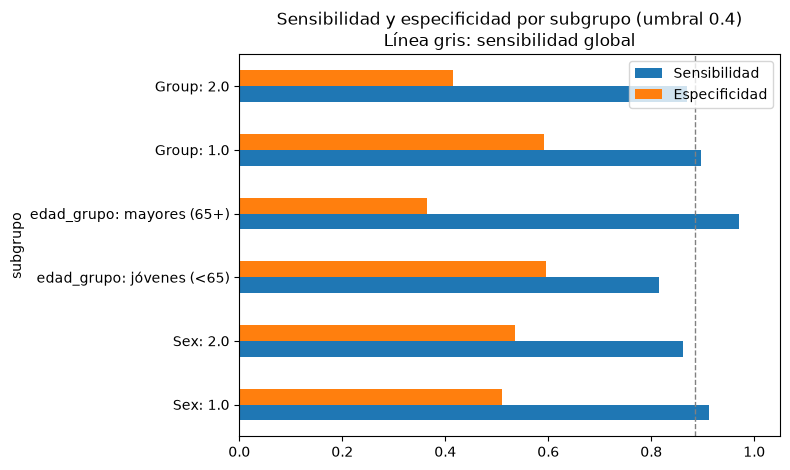

In [23]:
# Sesgo por subgrupo, en barras (umbral 0.4)
filas_s = []
for col in ["Sex", "edad_grupo", "Group"]:
    t_ = por_subgrupo(col)
    for _, r_ in t_.iterrows():
        filas_s.append({"subgrupo": f"{col}: {r_[col]}",
                        "Sensibilidad": r_["sens"], "Especificidad": r_["espec"]})

sesgo = pd.DataFrame(filas_s).set_index("subgrupo")
ax = sesgo.plot.barh(figsize=(8, 4.8))
ax.axvline(metricas(0.4)["sens"], color="gray", ls="--", lw=1)
ax.set_title("Sensibilidad y especificidad por subgrupo (umbral 0.4)\nLínea gris: sensibilidad global")
ax.set_xlim(0, 1.05)
plt.tight_layout()
plt.show()

### Análisis de errores por subgrupos

- De los 17 pacientes urgentes no detectados, 15 son menores de 65 años.
- La sensibilidad es menor en pacientes menores de 65 años (0,815) que en mayores de esa edad (0,970), lo que indica que el modelo detecta una mayor proporción de urgencias en el grupo de mayor edad.
- En pacientes mayores de 65 años, la especificidad es baja (0,364), lo que sugiere que el modelo clasifica como urgentes a muchos pacientes que no lo son.
- Por sexo las diferencias son pequeñas. Por hospital la sensibilidad es parecida (0,897 vs 0,870), pero la especificidad difiere más (0,591 vs 0,415). Con subgrupos tan pequeños no se puede concluir que haya diferencias reales, aunque conviene vigilarlo.

**Conclusión:** el modelo presenta más dificultades para detectar pacientes urgentes menores de 65 años. En los mayores, detecta casi todas las urgencias, pero genera más falsas alarmas. Estas diferencias deben interpretarse con cautela debido al tamaño de la muestra.

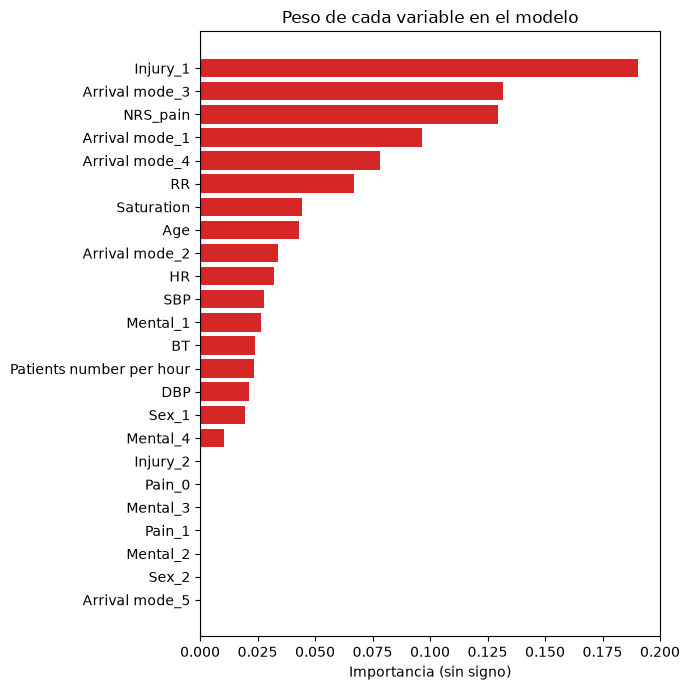

Posición de Age según el tamaño absoluto de su peso: 8 de 24
Las 5 variables con mayor peso: ['Injury_1', 'Arrival mode_3', 'NRS_pain', 'Arrival mode_1', 'Arrival mode_4']


In [24]:
# ¿Qué variables pesan más en el modelo?
clf_final = modelo.named_steps["clf"]
nombres = [n.replace("num__", "").replace("cat__", "")
           for n in modelo.named_steps["pre"].get_feature_names_out()]

if hasattr(clf_final, "coef_"):
    valores, etiqueta = np.ravel(clf_final.coef_), "Coeficiente (rojo: empuja a urgente, azul: a no urgente)"
elif hasattr(clf_final, "feature_importances_"):
    valores, etiqueta = clf_final.feature_importances_, "Importancia (sin signo)"
else:
    valores = None

if valores is None:
    print("El modelo elegido no expone pesos por variable; se omite esta gráfica.")
else:
    coef = pd.Series(valores, index=nombres).sort_values()
    fig, ax = plt.subplots(figsize=(7, 7))
    ax.barh(coef.index, coef.values, color=["#d62728" if v_ > 0 else "#1f77b4" for v_ in coef.values])
    ax.axvline(0, color="black", lw=0.8)
    ax.set_title("Peso de cada variable en el modelo")
    ax.set_xlabel(etiqueta)
    plt.tight_layout()
    plt.show()

    orden_abs = coef.abs().sort_values(ascending=False).index.tolist()
    print("Posición de Age según el tamaño absoluto de su peso:", orden_abs.index("Age") + 1, "de", len(orden_abs))
    print("Las 5 variables con mayor peso:", orden_abs[:5])

### Importancia de las variables

- Las variables más importantes para el modelo son `Injury_1`, `Arrival mode_3`, `NRS_pain`, `Arrival mode_1` y `Arrival mode_4`.
- Les siguen `RR`, `Saturation` y `Age`.
- La importancia indica cuánto contribuye cada variable al funcionamiento del modelo, pero no muestra si aumenta o disminuye la probabilidad de clasificar a un paciente como urgente.

**Conclusión:** el modelo se apoya principalmente en variables relacionadas con las lesiones, el modo de llegada al hospital y el nivel de dolor, seguidas de variables clínicas como la frecuencia respiratoria, la saturación de oxígeno y la edad.

---
## Umbral de caso crítico (R20)

A diferencia del umbral de 0.4, que clasifica a los pacientes como urgentes o no urgentes, el umbral crítico determina cuándo activar una alerta para el médico.

Para justificarlo, se analiza qué proporción de los pacientes que superan distintos umbrales pertenece a las categorías KTAS 1 y 2, correspondientes a los niveles de mayor gravedad.

In [25]:
ktas_test = df.loc[X_test.index, "KTAS_expert"]
graves = (ktas_test <= 2)

filas = []
for u in [0.6, 0.7, 0.8, 0.9]:
    marcados = proba >= u
    filas.append({"umbral": u,
                  "marcados": int(marcados.sum()),
                  "% realmente KTAS 1-2": round(graves[marcados].mean(), 3) if marcados.sum() else None,
                  "% de los KTAS 1-2 que captura": round(marcados[graves].mean(), 3)})
print(f"KTAS 1-2 en prueba: {int(graves.sum())} de {len(graves)}")
print(pd.DataFrame(filas).to_string())

KTAS 1-2 en prueba: 52 de 254
   umbral  marcados  % realmente KTAS 1-2  % de los KTAS 1-2 que captura
0     0.6       132                 0.242                          0.615
1     0.7       105                 0.295                          0.596
2     0.8        69                 0.377                          0.500
3     0.9        29                 0.483                          0.269


In [26]:
for u in [0.8, 0.9]:
    m = proba >= u
    print(u, "| urgentes entre los marcados:", round(y_test[m].mean(), 3),
          "| no urgentes marcados:", int((y_test[m] == 0).sum()))

0.8 | urgentes entre los marcados: 0.826 | no urgentes marcados: 12
0.9 | urgentes entre los marcados: 0.897 | no urgentes marcados: 3


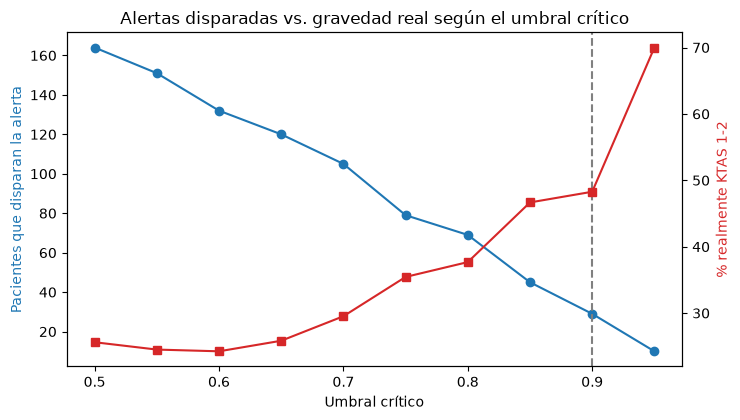

In [27]:
# Umbral crítico: cuántas alertas saltan y qué tan graves son
us = np.arange(0.5, 0.96, 0.05)
n_marc = [int((proba >= u).sum()) for u in us]
pct_graves = [graves.values[proba >= u].mean() * 100 if (proba >= u).sum() else np.nan for u in us]

fig, ax1 = plt.subplots(figsize=(7.5, 4.3))
ax1.plot(us, n_marc, "o-", color="#1f77b4")
ax1.set_xlabel("Umbral crítico")
ax1.set_ylabel("Pacientes que disparan la alerta", color="#1f77b4")
ax2 = ax1.twinx()
ax2.plot(us, pct_graves, "s-", color="#d62728")
ax2.set_ylabel("% realmente KTAS 1-2", color="#d62728")
ax1.axvline(0.9, color="gray", ls="--")
plt.title("Alertas disparadas vs. gravedad real según el umbral crítico")
plt.tight_layout()
plt.show()

In [28]:
graves_idx = graves.values
print("KTAS 1-2 marcados con umbral 0.4:", int((proba[graves_idx] >= 0.4).sum()), "de", int(graves_idx.sum()))

KTAS 1-2 marcados con umbral 0.4: 46 de 52


### Umbral crítico

- Con un umbral de **0,9**, la alerta se activa en 29 de los 254 pacientes (11 %): 26 son urgentes y 3 no urgentes.
- De estos 29 pacientes, 14 corresponden a KTAS 1–2, lo que representa el 48 % de las alertas y el 27 % de los 52 pacientes de esa categoría en el conjunto de prueba.
- Con un umbral de 0,8, la alerta se activaría en 69 pacientes (27 %), incluidos 12 no urgentes. Aunque permitiría detectar la mitad de los pacientes KTAS 1–2, también aumentaría la frecuencia de las alertas.
- Se mantiene el umbral de 0,9 para limitar la cantidad de alertas y reducir el riesgo de que el personal termine ignorándolas.
- Los pacientes graves que no alcanzan el umbral crítico de 0,9 siguen pudiendo ser clasificados como urgentes mediante el umbral general de 0,4.

**Conclusión:** se utiliza 0,9 para generar alertas críticas más selectivas, mientras que el umbral de 0,4 permite identificar a los pacientes urgentes que no alcanzan el nivel de alerta crítica.

---
### Guardar el modelo

Se guarda el pipeline entrenado con `joblib`, incluyendo el preprocesamiento y el modelo entrenado. También se almacenan la versión, las métricas, el umbral y la fecha en un diccionario.

Así, el servicio `ml` puede cargar el modelo al iniciar sin reentrenarlo, y el endpoint `GET /modelo` puede consultar su información.

In [29]:

m = metricas(0.4)  

paquete = {
    "modelo": modelo,
    "version": "1.1",
    "nombre_modelo": elegido_sup,
    "umbral": 0.4,
    "umbral_critico": 0.9,
    "columnas_num": cols_num,
    "columnas_cat": cols_cat,
    "metricas": {
        "auc_prueba": round(float(roc_auc_score(y_test, proba)), 3),
        "auc_cv": round(float(auc_cv.mean()), 3),
        "sensibilidad": float(m["sens"]), "especificidad": float(m["espec"]),
        "precision": float(m["prec"]), "f1": float(m["f1"]),
        "matriz_confusion": {"TN": int(m["TN"]), "FP": int(m["FP"]),
                             "FN": int(m["FN"]), "TP": int(m["TP"])},
    },
    "fecha": datetime.now().isoformat(timespec="seconds"),
    "sklearn": sklearn.__version__,
}

RUTA_ML = ruta_csv.parent.parent   # carpeta ml/, calculada desde la ruta del CSV (sin ruta fija)
(RUTA_ML / "modelo").mkdir(exist_ok=True)

joblib.dump(paquete, RUTA_ML / "modelo" / "ktas_modelo.joblib")
print(paquete["sklearn"], paquete["metricas"])

1.5.2 {'auc_prueba': 0.762, 'auc_cv': 0.833, 'sensibilidad': 0.884, 'especificidad': 0.523, 'precision': 0.718, 'f1': 0.793, 'matriz_confusion': {'TN': 56, 'FP': 51, 'FN': 17, 'TP': 130}}


### Métricas del modelo

El modelo obtiene un AUC de **0.762** en prueba y de **0.833** en validación cruzada. Con un umbral de 0.4, alcanza una sensibilidad de **0.884**, detectando el 88.4 % de los pacientes urgentes, y una especificidad de **0.523**. La precisión es de **0.718** y el F1 de **0.793**.

La matriz de confusión registra 130 verdaderos positivos (TP), 56 verdaderos negativos (TN), 51 falsos positivos (FP) y 17 falsos negativos (FN).

---

### Prueba del servicio de predicción

**1. Consultar la información del modelo**

Verifica que el modelo esté cargado y que sus métricas y umbrales estén disponibles.

```powershell
docker compose exec ml python -c "import urllib.request as u; print(u.urlopen('http://localhost:8001/modelo').read().decode())"
```

**2. Enviar un paciente de prueba**

Envía datos de ejemplo al endpoint de predicción.

```powershell
docker compose exec ml python -c "import json,urllib.request as u; d={'id_seudonimo':'p-001','sexo':2,'edad':75,'pacientes_por_hora':5,'modo_llegada':3,'lesion':1,'mental':1,'dolor':1,'nrs_dolor':8,'sbp':85,'dbp':50,'fc':125,'fr':26,'temperatura':38.5,'saturacion':86}; r=u.Request('http://localhost:8001/predecir',json.dumps(d).encode(),{'Content-Type':'application/json'}); print(u.urlopen(r).read().decode())"
```

**3. Resultado esperado**

- Probabilidad: muy alta (cercana a 1). El valor exacto cambia con XGBoost: anótalo después de correr la prueba (`0.9954` era el de la regresión logística).
- Clasificación: urgente (`true`).
- Caso crítico: `true`.
- Nivel: `critico`.
- Versión del modelo: `1.1`.

**4. Comprobar casos de diferente gravedad.**

El primer paciente de prueba tiene 75 años, saturación de oxígeno del 86 %, presión arterial baja y frecuencia cardíaca elevada. El modelo devuelve una probabilidad muy alta y lo clasifica como `critico`, activando la alerta.

También se puede probar el otro extremo con un paciente joven y signos vitales normales para comprobar si el modelo lo clasifica como `no urgente`. Así se verifica que el servicio responde ante perfiles clínicos diferentes.

---
### `POST /entrenar`

Se traslada el código de entrenamiento del cuaderno a un archivo `entrenar.py`, integrando la limpieza, la separación de datos, el pipeline y el guardado del modelo para que el servicio pueda reentrenarlo cuando se solicite.

Hay dos aspectos importantes:

- **Reutilización:** mantener las mismas reglas de preprocesamiento y entrenamiento del cuaderno.
- **Integración:** permitir que el endpoint `POST /entrenar` ejecute el proceso y guarde el nuevo modelo para su uso posterior.

## Preparamos y buscar el número de grupos (codo + silueta)

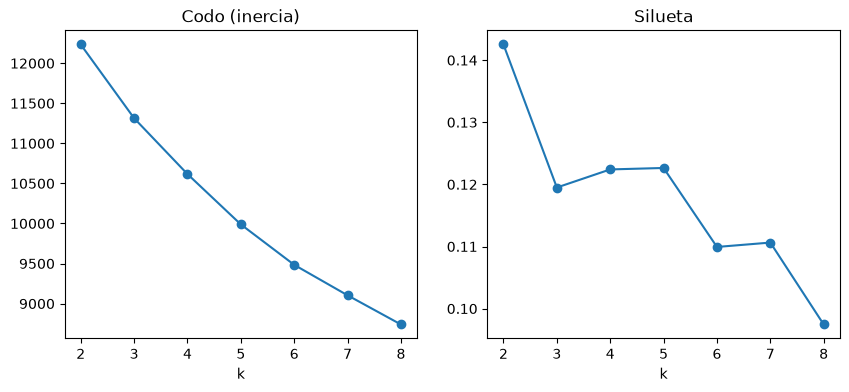

{2: np.float64(0.143), 3: np.float64(0.119), 4: np.float64(0.122), 5: np.float64(0.123), 6: np.float64(0.11), 7: np.float64(0.111), 8: np.float64(0.097)}


In [30]:

# Preprocesamiento del modelo (mediana , escala , one-hot) sobre todos los pacientes reales
Z = clone(pre).fit_transform(X)   # clone: no reajusta el 'pre' que usa el modelo final
if hasattr(Z, "toarray"):
    Z = Z.toarray()

ks = range(2, 9)
inercia, silueta = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(Z)
    inercia.append(km.inertia_)
    silueta.append(silhouette_score(Z, km.labels_))

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].plot(ks, inercia, marker="o"); ax[0].set_title("Codo (inercia)"); ax[0].set_xlabel("k")
ax[1].plot(ks, silueta, marker="o"); ax[1].set_title("Silueta"); ax[1].set_xlabel("k")
plt.show()
print(dict(zip(ks, np.round(silueta, 3))))

---
# Comparación de algoritmos de agrupamiento

En aprendizaje no supervisado **no existe un «AUC»**: no hay respuesta correcta contra la cual medir. Por eso se combinan cuatro criterios:

| Criterio | Qué mide | Se busca |
|---|---|---|
| **Silueta** | Qué tan separados están los grupos (−1 a 1) | Mayor |
| **Davies-Bouldin** | Cuánto se parecen los grupos entre sí | Menor |
| **ARI** frente a K-means | Cuánto coincide con otro método, sin importar cómo se numeren los grupos | Informativo |
| **Utilidad para el sistema (R07)** | Al menos 2 grupos y poder asignar a un paciente nuevo a su grupo | Obligatorio |

Se comparan cuatro algoritmos, cada uno con supuestos distintos: **K-means** (grupos redondos, pertenencia dura), **jerárquico de Ward** (árbol de uniones), **GMM** (campanas gaussianas con pertenencia suave) y **DBSCAN** (grupos por densidad, detecta ruido).

**Advertencia de honestidad.** La silueta y Davies-Bouldin favorecen a K-means *por construcción*, porque K-means optimiza justamente la compacidad de grupos redondos. Por eso estas métricas **orientan, pero no deciden solas**: pesan también la interpretación clínica y la utilidad para el sistema. Los datos mezclan variables numéricas y one-hot, así que GMM usa covarianza diagonal (con 1.267 pacientes y muchas columnas, la covarianza completa es inestable).

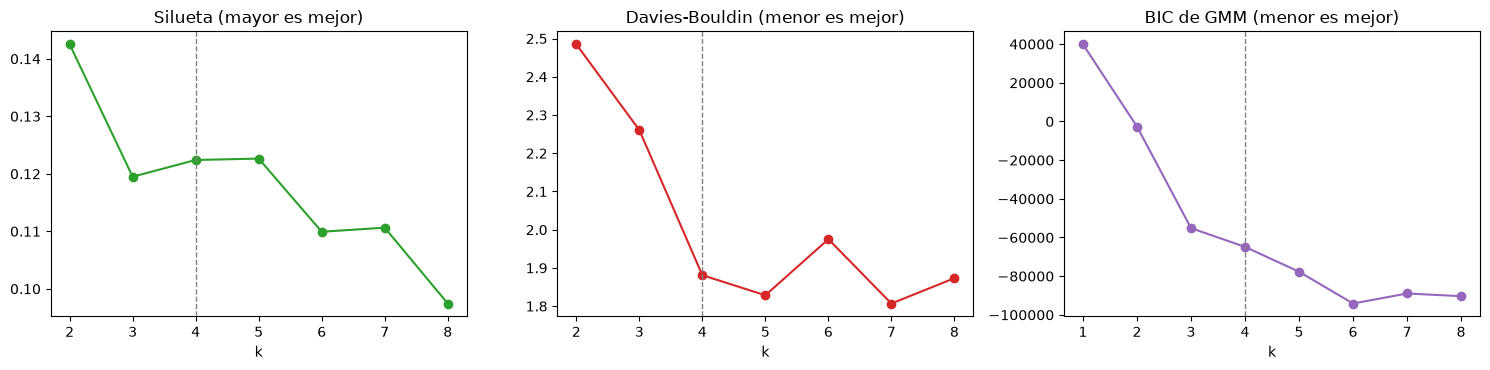

,silueta,davies_bouldin
k,,
2,0.143,2.485
3,0.119,2.261
4,0.122,1.881
5,0.123,1.828
6,0.110,1.975
7,0.111,1.807
8,0.097,1.873


In [31]:
from sklearn.metrics import davies_bouldin_score
from sklearn.mixture import GaussianMixture

# Tres criterios para elegir k (K-means) y el BIC de GMM
filas = []
for k_ in range(2, 9):
    etiq_ = KMeans(n_clusters=k_, n_init=10, random_state=42).fit_predict(Z)
    filas.append({"k": k_, "silueta": silhouette_score(Z, etiq_),
                  "davies_bouldin": davies_bouldin_score(Z, etiq_)})
criterios_k = pd.DataFrame(filas).set_index("k")

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    bic = {k_: GaussianMixture(n_components=k_, covariance_type="diag", n_init=3, random_state=42).fit(Z).bic(Z)
           for k_ in range(1, 9)}

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
criterios_k["silueta"].plot(ax=ax[0], marker="o", color="tab:green", title="Silueta (mayor es mejor)")
criterios_k["davies_bouldin"].plot(ax=ax[1], marker="o", color="tab:red", title="Davies-Bouldin (menor es mejor)")
pd.Series(bic).plot(ax=ax[2], marker="o", color="tab:purple", title="BIC de GMM (menor es mejor)")
for a_ in ax:
    a_.set_xlabel("k")
    a_.axvline(4, color="gray", ls="--", lw=1)
plt.tight_layout()
plt.show()
criterios_k.round(3)

### Selección del número de clusters

- La silueta alcanza su valor máximo con **k = 2 (0,143)**, aunque todos los valores son bajos (entre 0,097 y 0,143), lo que sugiere una separación débil entre los grupos.
- El índice Davies-Bouldin mejora principalmente entre k = 3 y k = 4, pasando de 2,26 a 1,88. A partir de ahí, las mejoras son menores.
- El BIC del modelo GMM continúa disminuyendo hasta aproximadamente k = 6, lo que favorece una solución con más grupos según este criterio.
- Los criterios no coinciden en un único número de clusters, por lo que no existe evidencia clara de una cantidad óptima de grupos según todas las métricas.
- Se elige **k = 4** por su interpretabilidad y porque el índice Davies-Bouldin presenta una mejora importante hasta ese punto y posteriormente las mejoras se reducen.

**Conclusión:** se seleccionan cuatro clusters como una solución práctica e interpretable, reconociendo que la separación entre los grupos es débil y que otros criterios favorecen diferentes cantidades de clusters.

In [32]:
from sklearn.cluster import AgglomerativeClustering, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import adjusted_rand_score
from scipy.cluster.hierarchy import dendrogram, linkage

K_ELEGIDO = 4
et = {}   # etiquetas de cada algoritmo

# --- K-means, jerárquico y GMM, todos con k = 4 (comparación justa)
et["K-means"] = KMeans(n_clusters=K_ELEGIDO, n_init=10, random_state=42).fit_predict(Z)
et["Jerárquico (Ward)"] = AgglomerativeClustering(n_clusters=K_ELEGIDO, linkage="ward").fit_predict(Z)
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    gmm_c = GaussianMixture(n_components=K_ELEGIDO, covariance_type="diag", n_init=3, random_state=42).fit(Z)
et["GMM"] = gmm_c.predict(Z)
zona_gris = float((gmm_c.predict_proba(Z).max(axis=1) < 0.6).mean() * 100)   # sin grupo claro

# --- DBSCAN: no pide k, pide eps. Se prueban varios eps tomados de la curva de distancias
MIN_MUESTRAS = 2 * len(cols_num + cols_cat)          # regla práctica: 2 x variables originales
dist_vecinos, _ = NearestNeighbors(n_neighbors=MIN_MUESTRAS).fit(Z).kneighbors(Z)
dist_k = np.sort(dist_vecinos[:, -1])
etiq_db, filas_db = {}, []
for q_ in [50, 70, 85, 95]:
    eps_ = float(np.percentile(dist_k, q_))
    e_ = DBSCAN(eps=eps_, min_samples=MIN_MUESTRAS).fit_predict(Z)
    etiq_db[q_] = e_
    filas_db.append({"percentil": q_, "eps": round(eps_, 2),
                     "grupos": len(set(e_[e_ != -1])), "% ruido": round((e_ == -1).mean() * 100, 1)})
print("DBSCAN con distintos eps:")
print(pd.DataFrame(filas_db).to_string(index=False))

# DBSCAN para la tabla: el eps con >= 2 grupos y mejor silueta; si ninguno, un solo grupo + ruido
def _sil(e):
    m_ = e != -1
    return silhouette_score(Z[m_], e[m_])
con_2 = {q_: e_ for q_, e_ in etiq_db.items() if len(set(e_[e_ != -1])) >= 2}
et["DBSCAN"] = con_2[max(con_2, key=lambda q_: _sil(con_2[q_]))] if con_2 else etiq_db[85]

# --- Tabla comparativa
def _tamanos(e):
    v_ = pd.Series(e[e != -1]).value_counts().sort_values(ascending=False)
    return ", ".join(str(int(x_)) for x_ in v_.values)

INFO = {"K-means": (True, "dura"), "Jerárquico (Ward)": (False, "dura"),
        "GMM": (True, "suave"), "DBSCAN": (False, "dura")}
filas = []
for nombre, e_ in et.items():
    ok = e_ != -1
    n_g = len(set(e_[ok]))
    s_, d_ = ((silhouette_score(Z[ok], e_[ok]), davies_bouldin_score(Z[ok], e_[ok])) if n_g >= 2 else (np.nan, np.nan))
    filas.append({"algoritmo": nombre, "grupos": n_g, "tamaños": _tamanos(e_),
                  "silueta": s_, "davies_bouldin": d_,
                  "ARI_vs_Kmeans": adjusted_rand_score(et["K-means"], e_),
                  "% ruido": round((e_ == -1).mean() * 100, 1),
                  "predice_nuevos": INFO[nombre][0], "pertenencia": INFO[nombre][1]})
tabla_nosup = pd.DataFrame(filas).set_index("algoritmo")

# Regla de decisión (fijada de antemano):
#   1) debe cumplir R07: >= 2 grupos y poder asignar pacientes nuevos
#   2) entre los que cumplen, empatan los que están a menos de 0.01 de la mejor silueta
#   3) entre los empatados gana el más simple
ORDEN_SIMPLICIDAD = ["K-means", "GMM", "Jerárquico (Ward)", "DBSCAN"]
elegibles = tabla_nosup[(tabla_nosup["grupos"] >= 2) & (tabla_nosup["predice_nuevos"])]
mejor_sil = elegibles["silueta"].max()
empatados_nosup = elegibles.index[elegibles["silueta"] >= mejor_sil - 0.01].tolist()
elegido_nosup = next(a_ for a_ in ORDEN_SIMPLICIDAD if a_ in empatados_nosup)

print(f"\nPacientes de GMM sin grupo claro (probabilidad máxima < 0.6): {zona_gris:.1f} %")
print(f"Cumplen R07 (>= 2 grupos y asignan pacientes nuevos): {', '.join(elegibles.index)}")
print(f"Empatados en silueta (a menos de 0.01 de la mejor): {', '.join(empatados_nosup)}")
print(f"Elegido según la regla: {elegido_nosup}")
tabla_nosup.round(3)

DBSCAN con distintos eps:
 percentil  eps  grupos  % ruido
        50 2.52       1     12.5
        70 2.76       1      6.2
        85 3.09       1      3.4
        95 3.69       1      1.7

Pacientes de GMM sin grupo claro (probabilidad máxima < 0.6): 0.0 %
Cumplen R07 (>= 2 grupos y asignan pacientes nuevos): K-means, GMM
Empatados en silueta (a menos de 0.01 de la mejor): K-means
Elegido según la regla: K-means


,grupos,tamaños,silueta,davies_bouldin,ARI_vs_Kmeans,% ruido,predice_nuevos,pertenencia
algoritmo,,,,,,,,
K-means,4,"535, 417, 309, 6",0.122,1.881,1.000,0.0,True,dura
Jerárquico (Ward),4,"675, 350, 241, 1",0.119,2.096,0.447,0.0,False,dura
GMM,4,"701, 467, 51, 48",0.109,3.629,0.510,0.0,True,suave
DBSCAN,1,1224,NaN,NaN,0.015,3.4,False,dura


### Comparación de algoritmos de clustering

- **K-means** obtuvo una silueta de 0,122 y un Davies-Bouldin de 1,88, presentando el mejor resultado general entre los algoritmos comparados.
- **Ward** obtuvo una silueta de 0,119 y un Davies-Bouldin de 2,10, además de generar un grupo formado por un solo paciente.
- **GMM** alcanzó una silueta de 0,109 y un Davies-Bouldin de 3,63, con grupos de 51 y 48 pacientes, lo que refleja una separación menos favorable según estas métricas.
- **DBSCAN** identificó un solo grupo con todos los valores de `eps` probados (el ruido bajó de 12,5 % a 1,7 % al subir `eps`; el 3,4 % de la tabla corresponde al percentil 85). Esto indica que no logró identificar varios grupos diferenciados con los parámetros evaluados.
- Solo K-means y GMM cumplen los requisitos de R07: generar al menos dos grupos y permitir asignar pacientes nuevos.

**Conclusión:** se selecciona **K-means** porque presenta mejores métricas de agrupamiento que las alternativas evaluadas y cumple los requisitos de R07. Sin embargo, las siluetas bajas indican que la separación entre los grupos sigue siendo débil.

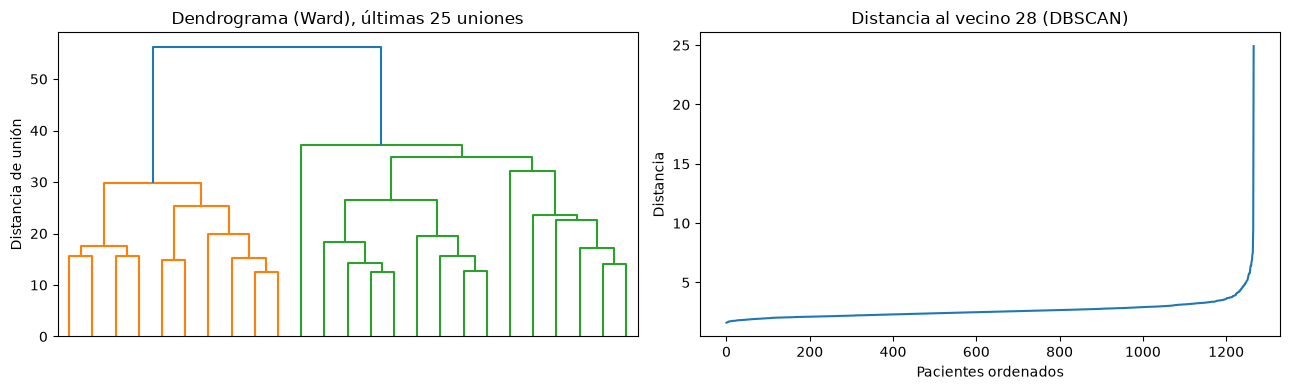

In [33]:
# Dendrograma (jerárquico) y curva de distancias (para elegir eps en DBSCAN)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
dendrogram(linkage(Z, method="ward"), truncate_mode="lastp", p=25, no_labels=True, ax=ax[0])
ax[0].set_title("Dendrograma (Ward), últimas 25 uniones")
ax[0].set_ylabel("Distancia de unión")
ax[1].plot(dist_k)
ax[1].set_title(f"Distancia al vecino {MIN_MUESTRAS} (DBSCAN)")
ax[1].set_xlabel("Pacientes ordenados")
ax[1].set_ylabel("Distancia")
plt.tight_layout()
plt.show()

### Cómo leer la comparación

- **Jerárquico:** los saltos verticales largos del dendrograma indican que se unieron grupos muy distintos. No tiene un modo directo de asignar a un paciente nuevo, así que no sirve como servicio.
- **GMM:** da pertenencia suave (por ejemplo, «70 % grupo 1, 28 % grupo 2»). La *zona gris* son los pacientes sin grupo claro; clínicamente es más honesto, porque hay pacientes entre dos perfiles.
- **DBSCAN:** no pide `k`, pide `eps`. Si con los valores razonables de `eps` solo encuentra **un grupo denso más ruido**, significa que no hay islas separadas por zonas vacías: coherente con la silueta baja. No cumpliría R07 (necesita al menos 2 grupos), pero su «ruido» es útil para detectar pacientes atípicos.
- **ARI frente a K-means:** 1 significa grupos idénticos y 0 acuerdo por azar. Un acuerdo moderado indica que hay pacientes en las fronteras entre grupos.



### Dendrograma y distancias

- El dendrograma muestra una separación marcada entre dos ramas principales, coherente con la silueta máxima en k = 2.
- La curva de distancias indica una nube de datos continua con pocos pacientes atípicos.

## Describir cada grupo

In [34]:
k = 4  
km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(Z)
res_c = X.copy()
res_c["cluster"] = km.labels_
res_c["urgente"] = y
res_c["KTAS"] = df.loc[X.index, "KTAS_expert"]

print(res_c.groupby("cluster").agg(
    n=("urgente", "size"), edad=("Age", "mean"), sbp=("SBP", "median"),
    fc=("HR", "median"), sat=("Saturation", "median"),
    nrs=("NRS_pain", "mean"), pct_urgente=("urgente", "mean")
).round(2))

           n   edad    sbp     fc   sat   nrs  pct_urgente
cluster                                                   
0        309  56.68  160.0   86.0  98.0  2.29         0.58
1        535  49.18  120.0   80.0  98.0  4.13         0.47
2        417  59.20  120.0   83.0  98.0  0.01         0.71
3          6  73.67  130.0  102.0  75.0  1.00         1.00


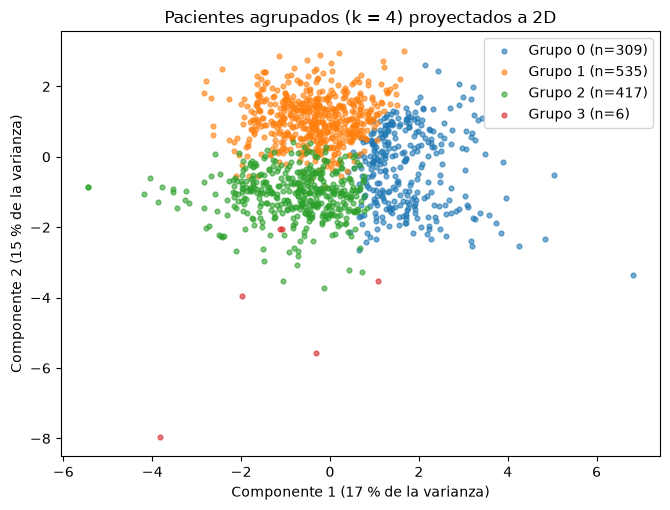

In [35]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=42).fit(Z)
Z2 = pca.transform(Z)

fig, ax = plt.subplots(figsize=(6.8, 5.2))
for c_ in sorted(res_c["cluster"].unique()):
    m_ = (res_c["cluster"].values == c_)
    ax.scatter(Z2[m_, 0], Z2[m_, 1], s=12, alpha=0.6, label=f"Grupo {c_} (n={int(m_.sum())})")
ax.set_xlabel(f"Componente 1 ({pca.explained_variance_ratio_[0]*100:.0f} % de la varianza)")
ax.set_ylabel(f"Componente 2 ({pca.explained_variance_ratio_[1]*100:.0f} % de la varianza)")
ax.set_title("Pacientes agrupados (k = 4) proyectados a 2D")
ax.legend()
plt.tight_layout()
plt.show()

Los grupos se solapan bastante, y el plano explica solo el 32 % de la varianza. Los 6 pacientes del grupo 3 aparecen dispersos en la periferia: son casos extremos más que un grupo denso.

## Perfil de cada grupo frente a la cohorte

Para interpretar un grupo no basta con ver sus promedios: hay que compararlos con los de **todos** los pacientes. La tabla siguiente muestra, para cada variable numérica, cuántas desviaciones estándar está cada grupo por encima (rojo) o por debajo (azul) del promedio general.

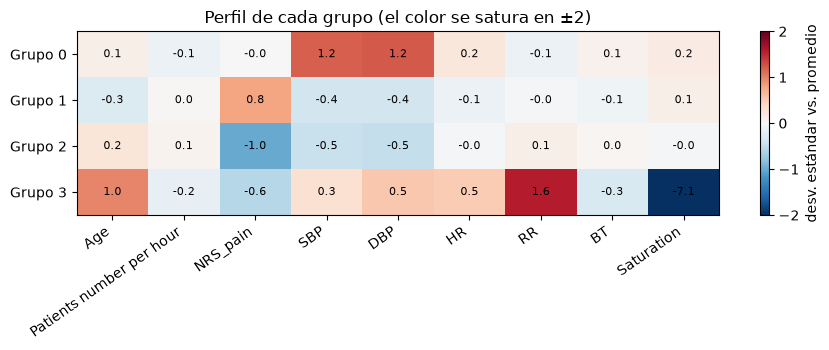

In [36]:
# Perfil de cada grupo en desviaciones estándar respecto al promedio de toda la cohorte
perfil_z = (res_c.groupby("cluster")[cols_num].mean() - X[cols_num].mean()) / X[cols_num].std()

fig, ax = plt.subplots(figsize=(9, 3.6))
im = ax.imshow(perfil_z, cmap="RdBu_r", vmin=-2, vmax=2, aspect="auto")
ax.set_xticks(range(len(cols_num)))
ax.set_xticklabels(cols_num, rotation=35, ha="right")
ax.set_yticks(range(len(perfil_z)))
ax.set_yticklabels([f"Grupo {c_}" for c_ in perfil_z.index])
for i_ in range(perfil_z.shape[0]):
    for j_ in range(perfil_z.shape[1]):
        ax.text(j_, i_, f"{perfil_z.iloc[i_, j_]:.1f}", ha="center", va="center", fontsize=8)
plt.colorbar(im, ax=ax, label="desv. estándar vs. promedio")
ax.set_title("Perfil de cada grupo (el color se satura en ±2)")
plt.tight_layout()
plt.show()

In [37]:
# Etiqueta y gravedad por grupo (los grupos se formaron SIN la etiqueta; recién ahora se mira)
dist_ktas = pd.crosstab(res_c["cluster"], res_c["KTAS"], normalize="index").round(2)
dist_ktas.columns = [f"KTAS {c_}" for c_ in dist_ktas.columns]
dist_ktas["% urgentes (KTAS 1-3)"] = (res_c.groupby("cluster")["urgente"].mean() * 100).round(1)
dist_ktas["% KTAS 1-2"] = ((res_c["KTAS"] <= 2).groupby(res_c["cluster"]).mean() * 100).round(1)
dist_ktas

,KTAS 1,KTAS 2,KTAS 3,KTAS 4,KTAS 5,% urgentes (KTAS 1-3),% KTAS 1-2
cluster,,,,,,,
0,0.01,0.19,0.38,0.37,0.05,57.9,19.7
1,0.00,0.13,0.34,0.48,0.05,47.1,13.5
2,0.05,0.21,0.45,0.21,0.08,71.0,26.1
3,0.33,0.33,0.33,0.00,0.00,100.0,66.7


El porcentaje de urgentes varía de **47,1 % (grupo 1)** a **71,0 % (grupo 2)**, con **57,9 % en el grupo 0**. Hay estructura real, pero **moderada**: incluso el grupo 2 tiene un 29 % de no urgentes, y el grupo 1 tiene un 47 % de urgentes.

El grupo 3 es **100 % urgente**, pero son solo 6 pacientes: 2 en cada nivel de KTAS 1, 2 y 3. Por tanto, el 66,7 % de KTAS 1–2 equivale a apenas **4 pacientes**.

In [38]:
# Nombre de cada grupo ASIGNADO POR CÓDIGO según su perfil.
# Los números (0, 1, 2, 3) dependen de la inicialización de K-means y pueden cambiar con otra
# versión de scikit-learn; el perfil no.
resumen_g = res_c.groupby("cluster").agg(
    sat=("Saturation", "median"), sbp=("SBP", "median"), nrs=("NRS_pain", "mean"))

c_hipox = resumen_g["sat"].idxmin()                    # la saturación más baja
resto = resumen_g.drop(c_hipox)
c_hta = resto["sbp"].idxmax()                          # la presión sistólica más alta de los demás
resto = resto.drop(c_hta)
c_sin_dolor = resto["nrs"].idxmin()                    # el menor dolor de los que quedan
c_general = resto.drop(c_sin_dolor).index[0]           # el que sobra

NOMBRES = {
    c_hipox: "Hipoxemia severa con frecuencia respiratoria alta",
    c_hta: "Presión arterial alta",
    c_sin_dolor: "Sin dolor y con alta proporción de urgentes",
    c_general: "Grupo general (dolor por encima del promedio, signos vitales normales)",
}
pd.Series(NOMBRES).sort_index().to_frame("nombre")

,nombre
0,Presión arterial alta
1,"Grupo general (dolor por encima del promedio, ..."
2,Sin dolor y con alta proporción de urgentes
3,Hipoxemia severa con frecuencia respiratoria alta


### Del grupo a la decisión

Interpretar los grupos «en términos de la problemática» (R07) es decir qué cambia, para quien atiende, saber que un paciente pertenece a cada uno.

| Grupo | Qué se observa | Qué apoya |
|---|---|---|
| **Hipoxemia severa con frecuencia respiratoria alta** | Saturación muy baja, frecuencia respiratoria alta y mayor edad; todos urgentes. Son pocos pacientes | Priorizar por saturación y respiración. El modelo no falla aquí, pero con tan pocos casos no se puede generalizar |
| **Presión arterial alta** | Presión sistólica y diastólica elevadas; el modelo se comporta como en el resto | Revisar presión y estado mental, y confirmar con el motivo de consulta |
| **Sin dolor y con alta proporción de urgentes** | El modelo marca como urgente a casi todos: las falsas alarmas superan con mucho lo esperado | Esperar falsas alarmas; confirmar con el motivo de consulta, que el modelo no usa |
| **Grupo general** (dolor por encima del promedio, signos vitales normales) | Urgentes y no urgentes se parecen mucho; se pierden más urgentes de los esperados | No descartar a un paciente solo porque el modelo dé una probabilidad baja; mirar el motivo de consulta |

Estas decisiones son apoyos para el juicio clínico, no reglas: el médico aprueba o rechaza cada reporte.

## ¿En qué grupo se confunde el modelo?

In [39]:


proba_all = cross_val_predict(modelo, X, y, cv=cv, method="predict_proba")[:, 1]
res_c["pred"] = (proba_all >= 0.4).astype(int)

def resumen(d):
    tn, fp, fn, tp = confusion_matrix(d["urgente"], d["pred"], labels=[0, 1]).ravel()
    return pd.Series({"n": len(d), "sens": tp / (tp + fn) if tp + fn else np.nan,
                      "espec": tn / (tn + fp) if tn + fp else np.nan,
                      "FN": fn, "FP": fp, "error": (fn + fp) / len(d)})

print(res_c.groupby("cluster").apply(resumen).round(3))

             n   sens  espec    FN    FP  error
cluster                                        
0        309.0  0.872  0.485  23.0  67.0  0.291
1        535.0  0.821  0.714  45.0  81.0  0.236
2        417.0  0.946  0.240  16.0  92.0  0.259
3          6.0  1.000    NaN   0.0   0.0  0.000


C:\Users\Admin\AppData\Local\Temp\ipykernel_19748\2332796175.py:10: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  print(res_c.groupby("cluster").apply(resumen).round(3))


### Rendimiento por cluster

- El grupo 1 concentra más urgencias no detectadas (45 urgentes no detectados), con una sensibilidad de 0,821.
- En el grupo 2, la especificidad es baja (0,240), por lo que se generan muchas falsas alarmas.
- El grupo 0 presenta el mayor error total (29,1 %).

### Zona de confusión: dos reglas

«Zona de confusión» es un grupo donde el modelo se equivoca más que en el conjunto. Se puede medir de dos maneras, y en triage **no son equivalentes**:

- **Por urgentes perdidos:** la sensibilidad del grupo es menor que la global. Es el error grave: un paciente urgente que el modelo deja pasar.
- **Por error total:** el error del grupo (urgentes perdidos más falsas alarmas) supera el error global. Incluye las falsas alarmas, que cuestan tiempo pero no ponen en riesgo al paciente.

In [40]:
# resumen() es la función de la celda de rendimiento por cluster
filas_z = [resumen(d_).rename(c_) for c_, d_ in res_c.groupby("cluster")]
zona = pd.DataFrame(filas_z)
glob = resumen(res_c)

zona["zona_por_perdidos"] = zona["sens"] < glob["sens"]
zona["zona_por_error"] = zona["error"] > glob["error"]
zona["zona_confusion"] = zona["zona_por_perdidos"] | zona["zona_por_error"]
zona["nombre"] = pd.Series(NOMBRES)

print(f"Global: sensibilidad {glob['sens']:.3f} | especificidad {glob['espec']:.3f} | error {glob['error']:.3f}")
zona[["nombre", "n", "sens", "espec", "FN", "FP", "error",
      "zona_por_perdidos", "zona_por_error", "zona_confusion"]].round(3)

Global: sensibilidad 0.885 | especificidad 0.551 | error 0.256


,nombre,n,sens,espec,FN,FP,error,zona_por_perdidos,zona_por_error,zona_confusion
0,Presión arterial alta,309.0,0.872,0.485,23.0,67.0,0.291,True,True,True
1,"Grupo general (dolor por encima del promedio, ...",535.0,0.821,0.714,45.0,81.0,0.236,True,False,True
2,Sin dolor y con alta proporción de urgentes,417.0,0.946,0.240,16.0,92.0,0.259,False,True,True
3,Hipoxemia severa con frecuencia respiratoria alta,6.0,1.000,NaN,0.0,0.0,0.000,False,False,False


In [41]:
from scipy.stats import binomtest

filas_p = []
for c_, d_ in res_c.groupby("cluster"):
    urg = d_["urgente"] == 1
    n_urg, n_no = int(urg.sum()), int((~urg).sum())
    fn_ = int((urg & (d_["pred"] == 0)).sum())
    fp_ = int((~urg & (d_["pred"] == 1)).sum())
    p_perd = binomtest(fn_, n_urg, 1 - glob["sens"], alternative="greater").pvalue if n_urg else np.nan
    p_fa = binomtest(fp_, n_no, 1 - glob["espec"], alternative="greater").pvalue if n_no else np.nan
    filas_p.append({"cluster": c_,
                    "FN": fn_, "FN_esperados": round(n_urg * (1 - glob["sens"]), 1), "p_perdidos": p_perd,
                    "FP": fp_, "FP_esperadas": round(n_no * (1 - glob["espec"]), 1), "p_falsas_alarmas": p_fa})

prueba = pd.DataFrame(filas_p).set_index("cluster")
ALFA = 0.05 / (2 * len(prueba))          # corrección: 4 grupos x 2 tipos de error
prueba["zona_perdidos_real"] = prueba["p_perdidos"] < ALFA
prueba["zona_falsas_alarmas_real"] = prueba["p_falsas_alarmas"] < ALFA
prueba["nombre"] = pd.Series(NOMBRES)
prueba.round(4)

,FN,FN_esperados,p_perdidos,FP,FP_esperadas,p_falsas_alarmas,zona_perdidos_real,zona_falsas_alarmas_real,nombre
cluster,,,,,,,,,
0,23,20.5,0.3122,67,58.4,0.0776,False,False,Presión arterial alta
1,45,28.9,0.0018,81,127.2,1.0000,True,False,"Grupo general (dolor por encima del promedio, ..."
2,16,33.9,0.9999,92,54.4,0.0000,False,True,Sin dolor y con alta proporción de urgentes
3,0,0.7,1.0000,0,0.0,NaN,False,False,Hipoxemia severa con frecuencia respiratoria alta


 `FN_esperados` es cuántos urgentes perdería el grupo si el modelo se comportara como en el conjunto; `FP_esperadas`, lo mismo para las falsas alarmas. Si lo observado supera mucho a lo esperado (p pequeño, con corrección por comparar varios grupos), la diferencia es real; si no, puede ser azar.

El grupo 1 pierde 45 urgentes frente a unos 29 esperados: es zona de confusión **por urgentes perdidos**. El grupo 2 genera 92 falsas alarmas frente a unas 54 esperadas: zona de confusión **por falsas alarmas**. En el grupo 0 las diferencias no se distinguen del azar.

### Sinteticos

In [42]:
rng = np.random.default_rng(42)
n_sint = {0: 60, 1: 60, 2: 60, 3: 10}   
cols_ruido = ["Age", "Patients number per hour", "NRS_pain", "SBP", "DBP", "HR", "RR", "BT", "Saturation"]

filas = []
for c, n in n_sint.items():
    base = res_c.loc[res_c["cluster"] == c, cols_num + cols_cat]
    sd, lo, hi = base[cols_ruido].std(), base[cols_ruido].min(), base[cols_ruido].max()
    m = base.sample(n, replace=True, random_state=42).reset_index(drop=True)
    for col in cols_ruido:
        m[col] = (m[col] + rng.normal(0, 0.2 * sd[col], n)).clip(lo[col], hi[col])
    m.loc[m["Pain"] == 0, "NRS_pain"] = 0
    for col in ["Age", "Patients number per hour", "NRS_pain", "SBP", "DBP", "HR", "RR", "Saturation"]:
        m[col] = m[col].round()
    m["BT"] = m["BT"].round(1)
    m["cluster"], m["origen"] = c, "sintetico"
    filas.append(m)

sinteticos = pd.concat(filas, ignore_index=True)
     
# Conteo por cluster (lo que devolverá el endpoint)
reales = res_c[["cluster"]].assign(origen="real")
print(pd.concat([reales, sinteticos[["cluster", "origen"]]]).groupby(["cluster", "origen"]).size().unstack())

sinteticos.to_csv(ruta_csv.parent / "pacientes_sinteticos.csv", index=False)

origen   real  sintetico
cluster                 
0         309         60
1         535         60
2         417         60
3           6         10


In [43]:
base0 = res_c.loc[res_c["cluster"] == 0, "Age"]
sd, lo, hi = base0.std(), base0.min(), base0.max()

medias = []
for s in range(500):
    r = np.random.default_rng(s)
    m = base0.sample(60, replace=True, random_state=s)
    m = (m + r.normal(0, 0.2 * sd, 60)).clip(lo, hi).round()
    medias.append(m.mean())
medias = np.array(medias)

print("media real:", round(base0.mean(), 1))
print("media de las 500 medias sintéticas:", round(medias.mean(), 2))
print("desviación de la media de 60:", round(medias.std(), 2))
print("proporción de generaciones con media >= 62.5:", (medias >= 62.5).mean())

media real: 56.7
media de las 500 medias sintéticas: 56.8
desviación de la media de 60: 2.4
proporción de generaciones con media >= 62.5: 0.008


**Nota sobre el grupo 0.** La edad media de los sintéticos (62,5 años) es mayor que la de los reales (56,7). Con 60 sintéticos remuestreados, la media puede desviarse unos 2,4 años por azar, y esta diferencia equivale a unas 2,4 veces esa cifra: poco frecuente para una sola comparación (alrededor del 1 % de las generaciones), pero no inusual entre las 20 comparaciones realizadas. Se verificó que el generador no tiene sesgo: el promedio de 500 generaciones con distintas semillas es 56,8 años (real: 56,7). En el grupo 3 (solo 6 reales) las diferencias son mayores (p. ej. saturación media 54 vs 66), por el tamaño tan pequeño del grupo y porque no se imputan los vacíos. Los sintéticos nunca se usan para entrenar ni evaluar el modelo, así que esta diferencia no afecta las métricas.

### Controles de calidad de los sintéticos

Los sintéticos se generan dentro de cada grupo: un paciente real del grupo, con un poco de ruido (20 % de la desviación estándar) y respetando el mínimo y el máximo de ese grupo. Antes de darlos por buenos se revisan cuatro cosas:

1. **¿Se reconocen en su grupo?** Se pasan por el **mismo** preprocesamiento y el mismo K-means. Si nacieron en el grupo 1, el modelo debería asignarlos al grupo 1 (es una prueba optimista: son copias de reales con poco ruido).
2. **¿Están dentro del rango clínico?** Ninguno debe salirse de lo observado en los pacientes reales (se cumple por construcción, porque se recorta al rango del grupo: verifica la implementación, no la calidad).
3. **¿Se parecen a los reales?** Se comparan medias por grupo.
4. **¿Ocupan la región de su grupo?** Se dibujan sobre el mismo PCA.

**Tres reglas que no se negocian:**
1. Un sintético **no agrega información nueva**: reproduce la que ya tenían los reales de su grupo.
2. **Nunca** se evalúa un modelo con sintéticos ni se presenta como validación clínica.
3. Todo sintético queda **marcado** (`origen = sintetico`) y **ligado a su cluster**.

In [44]:
# Mismo preprocesamiento (ajustado con los reales) y mismo K-means
pre_cl = clone(pre).fit(X)
Zs = pre_cl.transform(sinteticos[cols_num + cols_cat])
if hasattr(Zs, "toarray"):
    Zs = Zs.toarray()
reasignado = km.predict(Zs)

acierto = (reasignado == sinteticos["cluster"].to_numpy())
consistencia = pd.Series(acierto).groupby(sinteticos["cluster"].to_numpy()).mean()
cons_global = acierto.mean()
print("Sintéticos reconocidos en su propio grupo:")
print((consistencia * 100).round(1).astype(str) + " %")
print(f"Global: {cons_global:.1%}")

# Rango: ningún sintético fuera de lo observado en los pacientes reales
fuera = sum(int(((sinteticos[v] < X[v].min()) | (sinteticos[v] > X[v].max())).sum()) for v in cols_num)
print("Valores sintéticos fuera del rango real:", fuera)

# Medias por grupo: reales frente a sintéticos
vars_clave = ["Age", "SBP", "HR", "Saturation", "NRS_pain"]
comparacion = pd.concat({"real": res_c.groupby("cluster")[vars_clave].mean(),
                         "sintetico": sinteticos.groupby("cluster")[vars_clave].mean()}, axis=1)
comparacion.round(1)

Sintéticos reconocidos en su propio grupo:
0     95.0 %
1    100.0 %
2     96.7 %
3    100.0 %
dtype: object
Global: 97.4%
Valores sintéticos fuera del rango real: 0


real                                  sintetico               \
          Age    SBP    HR Saturation NRS_pain       Age    SBP    HR   
cluster                                                                 
0        56.7  166.3  87.7       97.7      2.3      62.5  168.3  84.5   
1        49.2  123.8  81.9       97.5      4.1      50.3  121.2  78.0   
2        59.2  121.3  83.7       96.9      0.0      60.0  122.3  85.3   
3        73.7  142.0  92.3       66.0      1.0      76.9  133.4  90.9   

                             
        Saturation NRS_pain  
cluster                      
0             97.8      2.1  
1             97.1      4.4  
2             96.5      0.0  
3             54.1      1.1

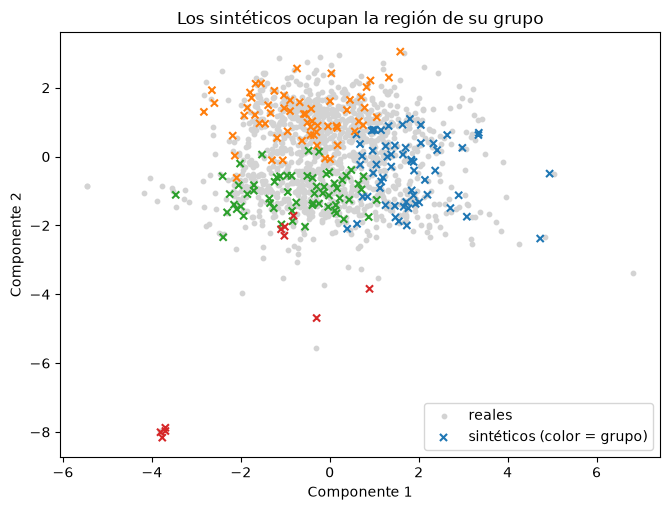

In [45]:
# Los sintéticos sobre el mismo plano PCA de los pacientes reales
Ps = pca.transform(Zs)
colores = plt.cm.tab10(sinteticos["cluster"].to_numpy().astype(int))

fig, ax = plt.subplots(figsize=(6.8, 5.2))
ax.scatter(Z2[:, 0], Z2[:, 1], c="lightgray", s=10, label="reales")
ax.scatter(Ps[:, 0], Ps[:, 1], c=colores, s=26, marker="x", label="sintéticos (color = grupo)")
ax.set_xlabel("Componente 1")
ax.set_ylabel("Componente 2")
ax.set_title("Los sintéticos ocupan la región de su grupo")
ax.legend()
plt.tight_layout()
plt.show()

In [46]:
def verificar(texto, condicion, extra=""):
    print(("OK  " if condicion else "FALLA"), texto, extra)

verificar("al menos 2 grupos", sinteticos["cluster"].nunique() >= 2)
verificar("todo grupo real tiene sintéticos (n_sinteticos > 0)", set(res_c["cluster"]) <= set(sinteticos["cluster"]))
verificar("todos marcados origen = sintetico", (sinteticos["origen"] == "sintetico").all())
verificar("ningún sintético fuera del rango real", fuera == 0, f"({fuera})")
verificar("más del 85 % se reconoce en su grupo", cons_global > 0.85, f"({cons_global:.1%})")

OK   al menos 2 grupos 
OK   todo grupo real tiene sintéticos (n_sinteticos > 0) 
OK   todos marcados origen = sintetico 
OK   ningún sintético fuera del rango real (0)
OK   más del 85 % se reconoce en su grupo (97.4%)


---
# Conclusión final: dos modelos, dos trabajos

El sistema usa **un modelo de cada familia**, porque cada una resuelve algo que la otra no puede:

| Necesidad | Quién la resuelve | Por qué la otra no puede |
|---|---|---|
| Decir si un paciente nuevo es urgente (R10, R20) | **Supervisado** | Los grupos no tienen etiqueta de urgencia |
| Describir perfiles de pacientes y generar sintéticos coherentes dentro de cada grupo (R07) | **No supervisado** | El clasificador solo da una probabilidad |
| Saber **dónde se equivoca** el modelo (lo pide R07) | **Las dos juntas** | Se necesitan los grupos y las predicciones |

Hay una precisión importante sobre el flujo: los grupos se forman **sin usar la etiqueta**; solo después se calcula el porcentaje de urgentes por grupo para interpretarlos.

Los pacientes sintéticos **nunca** se usan para entrenar ni evaluar. Sirven para poblar el sistema; no mejoran el AUC.

In [47]:
print("=" * 74)
print("CONCLUSIÓN FINAL")
print("=" * 74)

r_ = tabla_sup.loc[elegido_sup]
resumen_final = pd.DataFrame([
    {"Tarea": "Predecir urgencia (supervisado)", "Modelo elegido": elegido_sup,
     "Evidencia": f"AUC_cv {r_['AUC_cv']:.3f} ± {r_['desviacion']:.3f}; AUC prueba {roc_auc_score(y_test, proba):.3f}; "
                  f"{len(empatados)} modelo(s) empatado(s) con el mejor"},
    {"Tarea": "Agrupar pacientes (no supervisado)", "Modelo elegido": elegido_nosup,
     "Evidencia": f"k = {K_ELEGIDO}; silueta {tabla_nosup.loc[elegido_nosup, 'silueta']:.3f}; "
                  f"Davies-Bouldin {tabla_nosup.loc[elegido_nosup, 'davies_bouldin']:.2f}"},
]).set_index("Tarea")
print(resumen_final.to_string())



print("\nLimitaciones que se declaran:")
for l_ in ["No se usa el motivo de consulta.",
           "Saturación vacía en el 55 % de los registros (se imputa con la mediana).",
           "Solo dos hospitales de Corea: no se sabe si generaliza a Colombia.",
           "La prueba tiene 254 pacientes: las cifras cambian algo con otra partición.",
           "El modelo aprendió «urgente» (KTAS 1-3), no «crítico».",
           "La silueta es baja: los grupos son segmentos, no categorías naturales."]:
    print("  -", l_)

CONCLUSIÓN FINAL
                                   Modelo elegido                                                                     Evidencia
Tarea                                                                                                                          
Predecir urgencia (supervisado)           XGBoost  AUC_cv 0.833 ± 0.005; AUC prueba 0.762; 2 modelo(s) empatado(s) con el mejor
Agrupar pacientes (no supervisado)        K-means                                     k = 4; silueta 0.122; Davies-Bouldin 1.88

Limitaciones que se declaran:
  - No se usa el motivo de consulta.
  - Saturación vacía en el 55 % de los registros (se imputa con la mediana).
  - Solo dos hospitales de Corea: no se sabe si generaliza a Colombia.
  - La prueba tiene 254 pacientes: las cifras cambian algo con otra partición.
  - El modelo aprendió «urgente» (KTAS 1-3), no «crítico».
  - La silueta es baja: los grupos son segmentos, no categorías naturales.


---
## Verificación de que los textos coinciden con los resultados

Los textos en Markdown son fijos: no cambian solos si se vuelven a ejecutar las celdas. Esta celda compara las cifras clave citadas arriba con las calculadas. Si alguna dice **CAMBIÓ**, hay que actualizar el texto correspondiente.

In [48]:
def chequeo(nombre, valor, esperado, tol=0.0015):
    ok = abs(float(valor) - esperado) <= tol
    print("OK    " if ok else "CAMBIÓ", f"{nombre}: cuaderno {float(valor):.3f} | texto {esperado}")

_m = metricas(0.4)
chequeo("AUC cv XGBoost", tabla_sup.loc["XGBoost", "AUC_cv"], 0.833)
chequeo("AUC cv CatBoost", tabla_sup.loc["CatBoost", "AUC_cv"], 0.829)
chequeo("AUC cv regresión logística", tabla_sup.loc["Regresión logística", "AUC_cv"], 0.809)
chequeo("AUC prueba", roc_auc_score(y_test, proba), 0.762)
chequeo("Sensibilidad (0.4)", _m["sens"], 0.884)
chequeo("Especificidad (0.4)", _m["espec"], 0.523)
chequeo("FN (0.4)", _m["FN"], 17, tol=0)
chequeo("FP (0.4)", _m["FP"], 51, tol=0)
chequeo("Alertas críticas (>=0.9)", (proba >= 0.9).sum(), 29, tol=0)
chequeo("Silueta K-means", tabla_nosup.loc["K-means", "silueta"], 0.122)
chequeo("Davies-Bouldin K-means", tabla_nosup.loc["K-means", "davies_bouldin"], 1.88, tol=0.01)
chequeo("Tamaño del grupo más pequeño", pd.Series(et["K-means"]).value_counts().min(), 6, tol=0)
chequeo("% urgentes grupo 1", res_c.groupby("cluster")["urgente"].mean()[1] * 100, 47.1, tol=0.1)
chequeo("% urgentes grupo 2", res_c.groupby("cluster")["urgente"].mean()[2] * 100, 71.0, tol=0.1)
chequeo("FN grupo 1", prueba.loc[1, "FN"], 45, tol=0)
chequeo("FP grupo 2", prueba.loc[2, "FP"], 92, tol=0)
chequeo("Sintéticos reconocidos (%)", cons_global * 100, 97.4, tol=0.1)
chequeo("Varianza PCA 2 componentes (%)", pca.explained_variance_ratio_.sum() * 100, 32, tol=1)
chequeo("k con menor BIC (texto: ~6)", min(bic, key=bic.get), 6, tol=1)
print("Variables 6.ª a 8.ª por importancia (texto: RR, Saturation, Age):", orden_abs[5:8])

OK     AUC cv XGBoost: cuaderno 0.833 | texto 0.833
OK     AUC cv CatBoost: cuaderno 0.829 | texto 0.829
OK     AUC cv regresión logística: cuaderno 0.809 | texto 0.809
OK     AUC prueba: cuaderno 0.762 | texto 0.762
OK     Sensibilidad (0.4): cuaderno 0.884 | texto 0.884
OK     Especificidad (0.4): cuaderno 0.523 | texto 0.523
OK     FN (0.4): cuaderno 17.000 | texto 17
OK     FP (0.4): cuaderno 51.000 | texto 51
OK     Alertas críticas (>=0.9): cuaderno 29.000 | texto 29
OK     Silueta K-means: cuaderno 0.122 | texto 0.122
OK     Davies-Bouldin K-means: cuaderno 1.881 | texto 1.88
OK     Tamaño del grupo más pequeño: cuaderno 6.000 | texto 6
OK     % urgentes grupo 1: cuaderno 47.103 | texto 47.1
OK     % urgentes grupo 2: cuaderno 70.983 | texto 71.0
OK     FN grupo 1: cuaderno 45.000 | texto 45
OK     FP grupo 2: cuaderno 92.000 | texto 92
OK     Sintéticos reconocidos (%): cuaderno 97.368 | texto 97.4
OK     Varianza PCA 2 componentes (%): cuaderno 31.314 | texto 32
OK     k con m